In [10]:
%load_ext autoreload
%autoreload 2

from kontext.visualization import get_figs,plot_boxplots,space_plot,harmonize_target_colors
from kontext.utils import format_key,format_value


from utils.embedding import benchmark_path,run_benchmark_wrapper,run_benchmark
from utils.load_data import get_dataset_info,load_adata
from utils.visualization import plot_sample_heatmap,plot_dataset_rank_dotplot,plot_metric_vs_nobs,readable_sample_name,readable_dataset_name


import pandas as pd 
import submitit
import json
import matplotlib.pyplot as plt

plt.rcParams['figure.facecolor'] = '#fcf8f500'
plt.rcParams['axes.facecolor'] = '#fcf8f500'

from itables import init_notebook_mode
init_notebook_mode(all_interactive=True)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [11]:
# Where to save the results 
root = '/pasteur/helix/projects/ml4ig_hot/Users/aozierla/kontext_project/results/benchmark_2026_07'


ZESTA = [['ZESTA', 'zf3_1'], ['ZESTA', 'zf5_10'], ['ZESTA', 'zf10_14'], ['ZESTA', 'zf12_8'], ['ZESTA', 'zf12_9'], ['ZESTA', 'zf18_7'], 
         ['ZESTA', 'zf18_8'], ['ZESTA', 'zf18_9'], ['ZESTA', 'zf24_4'], ['ZESTA', 'zf24_7'], ['ZESTA', 'zf24_9'], ['ZESTA', 'zf24_10']]
ARTISTA = [['ARTISTA', '2DPI_1'], ['ARTISTA', '5DPI_2'], ['ARTISTA', '10DPI_3'], ['ARTISTA', '15DPI_1'], 
           ['ARTISTA', '20DPI_2'], ['ARTISTA', '30DPI'], ['ARTISTA', '60DPI']]
MOSTA = [['MOSTA', 'E9.5_E1S1'], ['MOSTA', 'E10.5_E1S1'], ['MOSTA', 'E11.5_E1S1'], 
         ['MOSTA', 'E12.5_E1S1'], ['MOSTA', 'E14.5_E1S1'], ['MOSTA', 'E16.5_E1S1']]
MERFISH = [['MBA', 'C57BL6J_1_053'], ['MBA', 'C57BL6J_1_082'], ['MBA', 'C57BL6J_1_117'], 
       ['MBA', 'C57BL6J_1_111'], ['MBA', 'C57BL6J_1_113']]
STEREO = ZESTA + ARTISTA + MOSTA 
BENCHMARK = STEREO + MERFISH

## Supplementary table 1

In [12]:
table_1 = []
for dataset,sample in STEREO :
    info = get_dataset_info()[dataset][sample]
#     print(dataset,sample,info['n_obs'],info['n_domains'])
    table_1 += [{'dataset':dataset,'section':sample,'name':readable_sample_name(sample),'n_cells':info['n_obs'],'total genes':info['n_var'],'n_domains':info['n_domains']}]
df1 = pd.DataFrame(table_1)
print(df1)
df1.to_csv('./kontext_reproducibility/figures/benchmark/table_stereo_info.csv')


    dataset     section                            name  n_cells  total genes  \
0     ZESTA       zf3_1               hour 3, section 1     1167         6261   
1     ZESTA      zf5_10              hour 5, section 10      563         1962   
2     ZESTA     zf10_14             hour 10, section 14     1231         2756   
3     ZESTA      zf12_8              hour 12, section 8     2081         4963   
4     ZESTA      zf12_9              hour 12, section 9     2588         5802   
5     ZESTA      zf18_7              hour 18, section 7     3475         7522   
6     ZESTA      zf18_8              hour 18, section 8     3048         9217   
7     ZESTA      zf18_9              hour 18, section 9     5935        12485   
8     ZESTA      zf24_4              hour 24, section 4     5271        12680   
9     ZESTA      zf24_7              hour 24, section 7     6318        13786   
10    ZESTA      zf24_9              hour 24, section 9     4708        13042   
11    ZESTA     zf24_10     

## Supplementary table 2 

In [13]:
table_2 = []
for dataset,sample in MERFISH :
    info = get_dataset_info()[dataset][sample]
#     print(dataset,sample,info['n_obs'],info['n_domains'])
    ccf = info['n_domains']['ccf_region_name']
    tissue = info['n_domains']['tissue']
    cell_type = info['n_domains']['cell_type']
    table_2 += [{'dataset':dataset,'section':sample,'name':readable_sample_name(sample),'n_cells':info['n_obs'],'total genes':info['n_var'],'ccf':ccf,'tissue':tissue,'cell type':cell_type}]
df2 = pd.DataFrame(table_2)
print(df2)
df2.to_csv('./kontext_reproducibility/figures/benchmark/table_merfish_info.csv')


  dataset        section         name  n_cells  total genes  ccf  tissue  \
0     MBA  C57BL6J_1_053  section 053    34126         1120   77       9   
1     MBA  C57BL6J_1_082  section 082    42117         1120  170      10   
2     MBA  C57BL6J_1_117  section 117    22862         1120   59       6   
3     MBA  C57BL6J_1_111  section 111    35171         1120   89       8   
4     MBA  C57BL6J_1_113  section 113    30864         1120   84       8   

   cell type  
0         19  
1         22  
2         21  
3         20  
4         21  


## Figure 1  - Input

... storing 'sample' as categorical


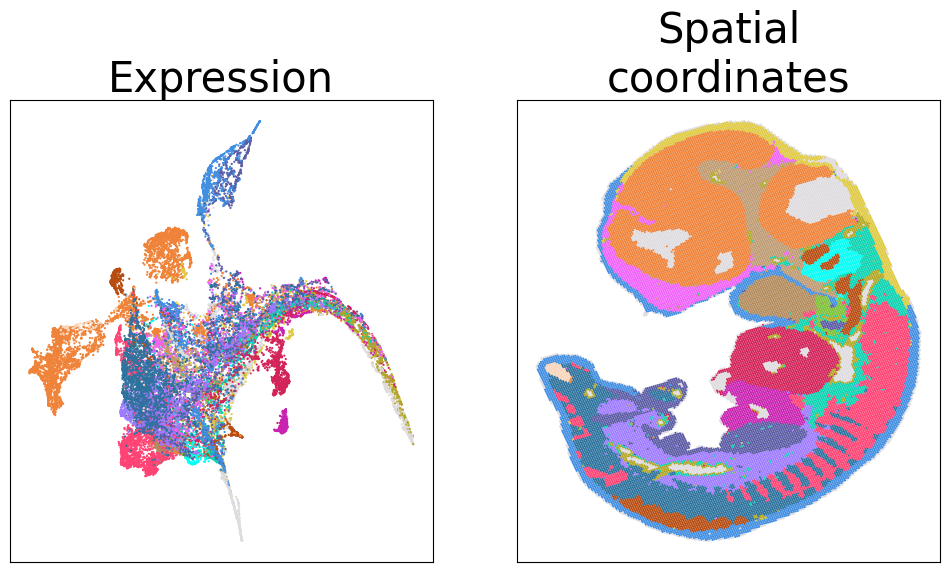

In [14]:
from utils.load_data import load_adata

from kontext.utils import pca_of_mat

from umap.umap_ import UMAP
from kontext.visualization import umap_plot
from kontext.utils import pca_on_adata

TO_SHOW = (
        #    ['MBA','C57BL6J_1_053'],
    #  ['ZESTA','zf24_4'],
     ['MOSTA','E11.5_E1S1'],
    #  ['ARTISTA','5DPI_2'],
           )
annotation = 'ccf_region_name'



i=-1
for dataset,sample in TO_SHOW:
    fig,(ax1,ax2) = get_figs(2)
    data = {'dataset':dataset,'sample':sample,'annotation':annotation} if dataset == 'MBA' else {'dataset':dataset,'sample':sample}     
    adata = load_adata(**data)
    pca_of_mat(adata=adata,mat = adata.X)
    adata.obsm[f'X_umap'] = UMAP(n_components=2).fit_transform(adata.obsm['X_pca'])

    
    umap_plot(adata,color='annotation',ax=ax1,s=10)
    space_plot(adata,color='annotation',ax=ax2,s=10)
    for ax in ax1,ax2:
        ax.get_legend().remove()
        ax.set_xlabel("")
        ax.set_ylabel("")

    ax1.set_title("Expression",fontsize=30)
    ax2.set_title("Spatial\ncoordinates",fontsize=30)
    plt.show()

## Figure 2A - Methods ranking

### Benchmark stereo-seq datasets 

The next cell has to be run twice. 
- First run to compute and save the results of each triplet `method-section-seed`. 
- Second run to load all the results in the `results` dict that will be used to display the scores. 

Additional information : 
- Methods can be run either locally or on a slurm cluster via `submitit`. Uncomment the right block according to your needs. 
- `run_all` : if True, all `method-section-seed`combinations will be run independantly from their 
- Prints allow to keep track of what is happening. 



In [15]:


min_seed,max_seed = 0,100
seeds = range(min_seed,max_seed)
run_all = False # if True, run the benchmark for all the parameters of the loop, otherwise, runs only the parameters for which the result file is missing.  

methods = {
'Kontext':{'additional_info':{'name':'Kontext'},'matrix':'Kontext','embedding':{"sigma_e":1, "snn":20, 'alpha':1/2},'spatial_domains':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'large2svg'}},#sparse_hvg
'BANKSY':{'matrix':'BANKSY','additional_info':{'name':'BANKSY'},'embedding':{'k_geom': 18, 'nbr_weight_decay': 'scaled_gaussian', 'm': 1, 'param_lambda': 0.4, 'n_comps': 50},'spatial_domains':{'clustering':'gmm','seed':0},'preprocessing':{'preprocessing':'BANKSY'}},
'SEDR':{'matrix':'SEDR','additional_info':{'name':'SEDR gmm'},'embedding':{'seed':0},'spatial_domains':{'clustering':'gmm','seed':0},'preprocessing':{'preprocessing':'SEDR'}},
'GraphST':{'matrix':'GraphST','additional_info':{'name':'GraphST gmm'},'embedding':{'seed':0},'spatial_domains':{'clustering':'gmm','seed':0},'preprocessing':{'preprocessing':None}},
}

total_torun = 0
total_done = 0
total_missing = 0
total = 0
results = {}

for dataset,sample in STEREO[:]:
    print(dataset,sample,get_dataset_info()[dataset][sample]['n_obs'])
    data = {'dataset':dataset,'sample':sample}
    results[f'{dataset}+{sample}'] = []
    for name,param0 in methods.items():    
            matrix = param0['matrix']
            executor_params = {
                        'slurm_partition':'common' if matrix in ['Kontext','BANKSY'] else 'ml4ig_gpu',
                        'slurm_cpus_per_task':1,
                        'slurm_array_parallelism':100,
                        'slurm_mem':('50G' if dataset=='MOSTA' else '5G') if matrix in ['Kontext','BANKSY'] else ('200G' if dataset=='MOSTA' else '15G'),#get_needed_mem(dataset,sample,step='all'),
                        'timeout_min':600,
                        'slurm_job_name':f'{name}_{sample}',
                        'slurm_srun_args':["--cpu-bind=none",'--nice=19'],
                        'slurm_gres': None if matrix in ['Kontext','BANKSY'] else 'gpu:1',
                        }

            params_all = []
            params_done = []
            params_missing = []

            for seed in seeds:
                param = {k:v.copy() if isinstance(v,dict) else v for k,v in param0.items()}
                param['data'] = data
                param['root'] = root
                if 'seed' in param['embedding']:
                    param['embedding']['seed'] = seed
                if 'seed' in param['spatial_domains']:
                    param['spatial_domains']['seed'] = seed
                signature = "_".join(f"{format_key(k)}{format_value(v)}" for k, v in {'matrix':param['matrix'],**param['preprocessing'],**param['embedding'],**param['spatial_domains']}.items() if v is not None and k!='additional_info')
                path = benchmark_path(data,root=root)
                p = path / f'{signature}.json'
                params_all += [param]
                
                if not p.exists():
                    params_missing += [param]
                else:
                    params_done += [param]
                    with open(p, "r") as f:
                        out = json.load(f)
                    results[f'{dataset}+{sample}'] += [out]

#### Uncomment to run benchmark locally in the loop
                # run_benchmark_wrapper(param)
                # run_example(**param)

####

            executor = submitit.AutoExecutor(folder=f"logs3/benchmark_{dataset}_{sample}/{matrix}/")
            executor.update_parameters(**executor_params ) 
            params_torun = params_all if run_all else params_missing
            n_torun = len(params_all) if run_all else len(params_missing)
            n_done = len(params_done)
            n_missing = len(params_missing)
            total_torun += n_torun
            total_done += n_done
            total_missing += n_missing

            print(f'{dataset} {sample} {matrix} to_run={n_torun} done={n_done} missing={n_missing} total_torun={total_torun} total_done={total_done} total_missing={total_missing}')

#### Uncomment to submit jobs with submitit

            # print(executor_params)
            # if len(params_torun)>0:
            #     jobs = executor.map_array(run_benchmark_wrapper,params_torun)

#####



ZESTA zf3_1 1167
ZESTA zf3_1 Kontext to_run=0 done=100 missing=0 total_torun=0 total_done=100 total_missing=0
ZESTA zf3_1 BANKSY to_run=0 done=100 missing=0 total_torun=0 total_done=200 total_missing=0
ZESTA zf3_1 SEDR to_run=0 done=100 missing=0 total_torun=0 total_done=300 total_missing=0
ZESTA zf3_1 GraphST to_run=0 done=100 missing=0 total_torun=0 total_done=400 total_missing=0
ZESTA zf5_10 563
ZESTA zf5_10 Kontext to_run=0 done=100 missing=0 total_torun=0 total_done=500 total_missing=0
ZESTA zf5_10 BANKSY to_run=0 done=100 missing=0 total_torun=0 total_done=600 total_missing=0
ZESTA zf5_10 SEDR to_run=0 done=100 missing=0 total_torun=0 total_done=700 total_missing=0
ZESTA zf5_10 GraphST to_run=0 done=100 missing=0 total_torun=0 total_done=800 total_missing=0
ZESTA zf10_14 1231
ZESTA zf10_14 Kontext to_run=0 done=100 missing=0 total_torun=0 total_done=900 total_missing=0
ZESTA zf10_14 BANKSY to_run=0 done=100 missing=0 total_torun=0 total_done=1000 total_missing=0
ZESTA zf10_14 SED

### Benchmark Mouse Brain Atlas sections

In [16]:

min_seed,max_seed = 0,100
seeds = range(min_seed,max_seed)
run_all = False # if True, run the benchmark for all the parameters of the loop, otherwise, runs only the parameters for which the result file is missing.  
annotations = ['ccf_region_name','tissue','cell_type']

methods = {
'Kontext a=0.0':{'additional_info':{'name':'a=0.0'},'matrix':'Kontext',     'embedding':{"sigma_e":1, "snn":20, 'alpha':0.0},'spatial_domains':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'xenium'}},#image'}},
'Kontext a=0.1':{'additional_info':{'name':'a=0.1'},'matrix':'Kontext',     'embedding':{"sigma_e":1, "snn":20, 'alpha':0.1},'spatial_domains':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'xenium'}},#image'}},
'Kontext a=0.2':{'additional_info':{'name':'a=0.2'},'matrix':'Kontext',     'embedding':{"sigma_e":1, "snn":20, 'alpha':0.2},'spatial_domains':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'xenium'}},#image'}},
'Kontext a=0.3':{'additional_info':{'name':'a=0.3'},'matrix':'Kontext',     'embedding':{"sigma_e":1, "snn":20, 'alpha':0.3},'spatial_domains':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'xenium'}},#image'}},
'Kontext a=0.4':{'additional_info':{'name':'a=0.4'},'matrix':'Kontext',     'embedding':{"sigma_e":1, "snn":20, 'alpha':0.4},'spatial_domains':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'xenium'}},#image'}},
'Kontext a=0.5':{'additional_info':{'name':'a=0.5'},'matrix':'Kontext',     'embedding':{"sigma_e":1, "snn":20, 'alpha':0.5},'spatial_domains':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'xenium'}},#image'}},
'Kontext a=0.6':{'additional_info':{'name':'a=0.6'},'matrix':'Kontext',     'embedding':{"sigma_e":1, "snn":20, 'alpha':0.6},'spatial_domains':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'xenium'}},#image'}},
'Kontext a=0.7':{'additional_info':{'name':'a=0.7'},'matrix':'Kontext',     'embedding':{"sigma_e":1, "snn":20, 'alpha':0.7},'spatial_domains':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'xenium'}},#image'}},
'Kontext a=0.8':{'additional_info':{'name':'a=0.8'},'matrix':'Kontext',     'embedding':{"sigma_e":1, "snn":20, 'alpha':0.8},'spatial_domains':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'xenium'}},#image'}},
'Kontext a=0.9':{'additional_info':{'name':'a=0.9'},'matrix':'Kontext',     'embedding':{"sigma_e":1, "snn":20, 'alpha':0.9},'spatial_domains':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'xenium'}},#image'}},
'Kontext a=1.0':{'additional_info':{'name':'a=1.0'},'matrix':'Kontext',     'embedding':{"sigma_e":1, "snn":20, 'alpha':1.0},'spatial_domains':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'xenium'}},#image'}},
'BANKSY':{'matrix':'BANKSY','additional_info':{'name':'BANKSY'},'embedding':{'k_geom': 18, 'nbr_weight_decay': 'scaled_gaussian', 'm': 1, 'param_lambda': 0.4, 'n_comps': 50},'spatial_domains':{'clustering':'gmm','seed':0},'preprocessing':{'preprocessing':'BANKSY'}},
'SEDR':{'additional_info':{'name':'SEDR gmm'},'matrix':'SEDR',              'embedding':{'seed':0},'spatial_domains':{'clustering':'gmm','seed':0} ,'preprocessing':{'preprocessing':'SEDR'}},
'GraphST':{'matrix':'GraphST','additional_info':{'name':'GraphST gmm'},'embedding':{'seed':0},'spatial_domains':{'clustering':'gmm','seed':0},'preprocessing':{'preprocessing':None}},
}

total_torun = 0
total_done = 0
total_missing = 0
total = 0
# results = {}
nerr = 0
for annotation in  annotations:
    for dataset,sample in MERFISH:
        print(dataset,sample,annotation)
        data = {'dataset':dataset,'sample':sample,'annotation':annotation}
        results[f'{dataset}_{annotation}+{sample}'] = []
        for name,param0 in methods.items():    
            matrix = param0['matrix'] 
            executor_params = {
                        'slurm_partition':'common' if matrix in ['Kontext','BANKSY'] else 'ml4ig_gpu',
                        'slurm_cpus_per_task':1,
                        'slurm_array_parallelism':100,
                        'slurm_mem':'5G' if matrix in ['Kontext','BANKSY'] else '80G',#get_needed_mem(dataset,sample,step='all'),
                        'timeout_min':180,
                        'slurm_job_name':f'{name}_{sample}_{annotation}',
                        'slurm_srun_args':["--cpu-bind=none"],
                        'slurm_gres': None if matrix in ['Kontext','BANKSY'] else 'gpu:1',
                        }

            params_all = []
            params_done = []
            params_missing = []
            for seed in seeds:
                param = {k:v.copy() if isinstance(v,dict) else v for k,v in param0.items()}
                param['data'] = data
                param['root'] = root
                if matrix == 'Kontext':
                    param['preprocessing']['preprocessing'] = 'xenium'
                if 'seed' in param['embedding']:
                    param['embedding']['seed'] = seed
                if 'seed' in param['spatial_domains']:
                    param['spatial_domains']['seed'] = seed

                signature = "_".join(f"{format_key(k)}{format_value(v)}" for k, v in {'matrix':param['matrix'],**param['preprocessing'],**param['embedding'],**param['spatial_domains']}.items() if v is not None and k!='additional_info')
                path = benchmark_path(data,root=root)
                p = path / f'{signature}.json'
                params_all += [param]
                
                if not p.exists():
                    params_missing += [param]
                else:
                    params_done += [param]
                    try:
                        with open(p, "r") as f:
                            out = json.load(f)
                    except:
                        print(p)
                        nerr+=1
                    results[f'{dataset}_{annotation}+{sample}'] += [out]

#### Uncomment to run benchmark locally in the loop
    
                # run_benchmark_wrapper(param)

####



            executor = submitit.AutoExecutor(folder=f"logs3/benchmark_{dataset}_{sample}_{annotation}/{name}/")
            executor.update_parameters(**executor_params ) 

            params_torun = params_all if run_all else params_missing
            n_torun = len(params_all) if run_all else len(params_missing)
            n_done = len(params_done)
            n_missing = len(params_missing)
            total_torun += n_torun
            total_done += n_done
            total_missing += n_missing
            print(f'err{nerr} {dataset} {sample} {annotation} {matrix} to_run={n_torun} done={n_done} missing={n_missing} total_torun={total_torun} total_done={total_done} total_missing={total_missing}')



#### Uncomment to submit jobs with submitit

            # if len(params_torun)>0:
            #     jobs = executor.map_array(run_benchmark_wrapper,params_torun)
                
#####

print(results)



MBA C57BL6J_1_053 ccf_region_name
err0 MBA C57BL6J_1_053 ccf_region_name Kontext to_run=0 done=100 missing=0 total_torun=0 total_done=100 total_missing=0
err0 MBA C57BL6J_1_053 ccf_region_name Kontext to_run=0 done=100 missing=0 total_torun=0 total_done=200 total_missing=0
err0 MBA C57BL6J_1_053 ccf_region_name Kontext to_run=0 done=100 missing=0 total_torun=0 total_done=300 total_missing=0
err0 MBA C57BL6J_1_053 ccf_region_name Kontext to_run=0 done=100 missing=0 total_torun=0 total_done=400 total_missing=0
err0 MBA C57BL6J_1_053 ccf_region_name Kontext to_run=0 done=100 missing=0 total_torun=0 total_done=500 total_missing=0
err0 MBA C57BL6J_1_053 ccf_region_name Kontext to_run=0 done=100 missing=0 total_torun=0 total_done=600 total_missing=0
err0 MBA C57BL6J_1_053 ccf_region_name Kontext to_run=0 done=100 missing=0 total_torun=0 total_done=700 total_missing=0
err0 MBA C57BL6J_1_053 ccf_region_name Kontext to_run=0 done=100 missing=0 total_torun=0 total_done=800 total_missing=0
err0 M

IOPub data rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_data_rate_limit`.

Current values:
ServerApp.iopub_data_rate_limit=1000000.0 (bytes/sec)
ServerApp.rate_limit_window=3.0 (secs)



### Filter and rename the results 

In [17]:
results_heatmap = {}
for dataset,sample in BENCHMARK:
    for annotation in annotations:
        if dataset == 'MBA':
            ds = f'{dataset}_{annotation}+{sample}'
        else:
            ds = f'{dataset}+{sample}'
        if ds not in results:
            continue

        res = results[ds]
        new_res = []
        new_res_stereo = []
        new_res_merfish = []
        new_res_fixed_alpha = []

        for run in res:
            i = run.copy()
            if i['matrix'] != 'Kontext':
                i['name'] = i['matrix']
            i['dataset'] = f'{dataset} {annotation}'.replace('MBA_','MBA ')
            if i['matrix'] == 'Kontext':
                i['name'] = i['matrix']
                if 'alpha' in i and dataset=='MBA':
                    i['name'] = 'Kontext' if (annotation == 'ccf_region_name' and i['alpha']==0) or (annotation == 'tissue' and i['alpha']==0.1) or (annotation == 'cell_type' and i['alpha']==1) else 'ignore'
                if 'alpha' in i and dataset!='MBA':
                    i['name'] = 'Kontext' if i['alpha']==1/2 else 'ignore'
            if i['name'] != 'ignore':
                new_res += [i]
        results_heatmap[ds] = new_res

# print(results[f'{dataset}+{sample}_{annotation}'])

### Plot Figure  2A 

ARI
NMI
Homogeneity
Completeness


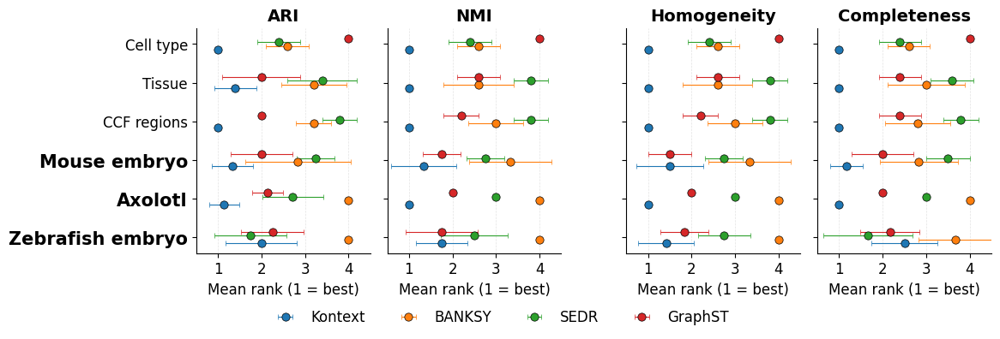

In [18]:
fig,axes,df1 = plot_dataset_rank_dotplot(results_heatmap,metrics=('ARI','NMI','HOM','COM'),fontsize=12)

def replace(tick):
    replacement = {'MBA_':'','cell_type':'Cell type','tissue':'Tissue','ccf_region_name':'CCF regions'}
    for old,new in replacement.items():
        tick._text = tick._text.replace(old,new)

    return(tick)


yticks = []
axes[0].set_yticklabels([readable_dataset_name(replace(tick).get_text()) for tick in axes[0].get_yticklabels()], rotation=0, fontsize=12) 
for tick in axes[0].get_yticklabels():
    if ('embryo' in tick._text) or ('Axolotl' in tick._text):# ['MOSTA','ARTISTA','ZESTA']:
        # tick.set_text(readable_dataset_name(tick._text)) 
        tick.set_fontweight('bold')
        tick.set_fontsize(15)


for ax in axes:
    title = ax.get_title()
    if title == 'HOM':
        ax.title.set_text('Homogeneity')
    if title == 'COM':
        ax.title.set_text('Completeness')

for ax in axes:
    print(ax.get_title())
plt.tight_layout(rect=[0, 0.08, 1, 1])

gap = 0.05  
for ax in axes[:2]:  
    p = ax.get_position()
    ax.set_position([p.x0 - gap/2, p.y0, p.width, p.height])
for ax in axes[2:]:   
    p = ax.get_position()
    ax.set_position([p.x0 + gap/2, p.y0, p.width, p.height])

# fig.savefig('kontext_project/figures/benchmark/benchmark_1a_ranks.pdf')

## Figure 2B - space plots of spatial domains

... storing 'sample' as categorical
... storing 'sample' as categorical


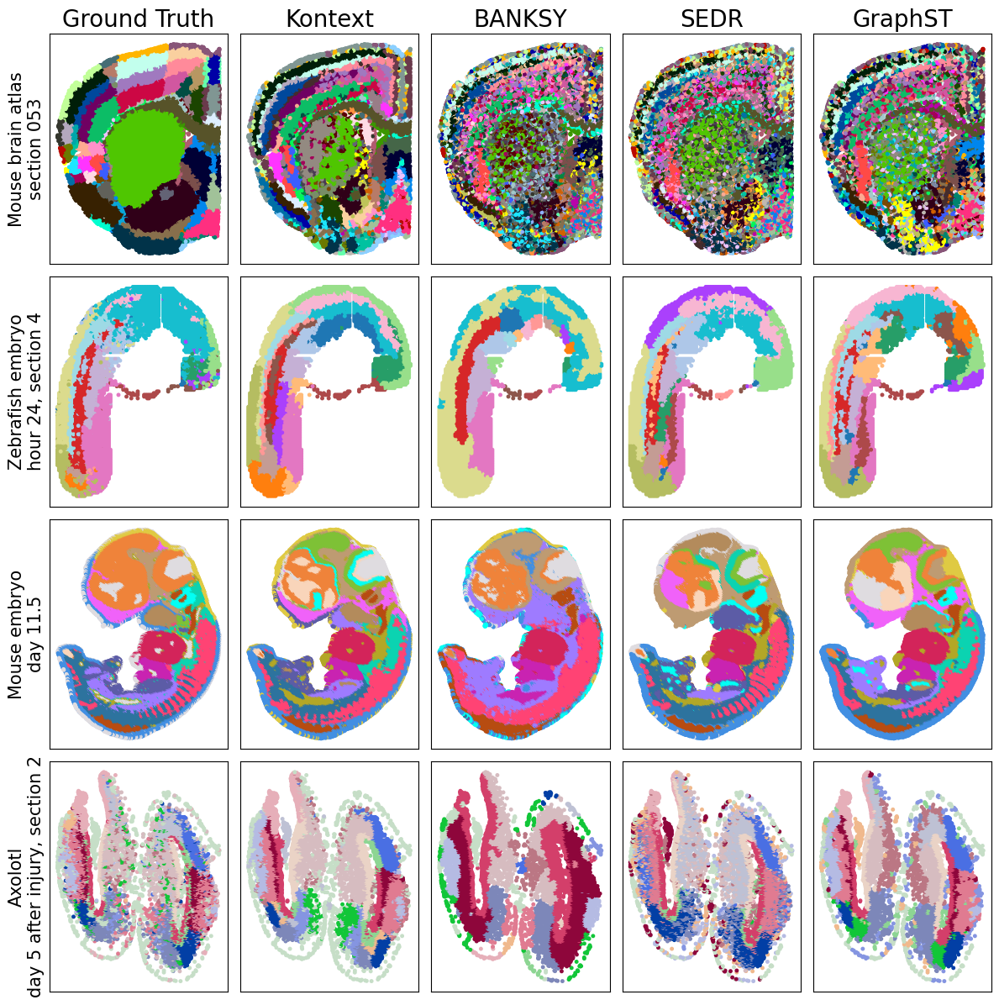

In [19]:
seed = 0
run_all = False # if True, run the benchmark for all the parameters of the loop, otherwise, runs only the parameters for which the result file is missing.  


methods = {
'Kontext':{'matrix':'Kontext','additional_info':{'name':'sparse_hvg pp'},'embedding':{"sigma_e":1, "snn":20, 'alpha':1/2},'spatial_domains':{'clustering':'gmm','seed':0},'preprocessing':{'preprocessing':'large2svg'}},
'BANKSY':{'matrix':'BANKSY','additional_info':{'name':'BANKSY'},'embedding':{'k_geom': 18, 'nbr_weight_decay': 'scaled_gaussian', 'm': 1, 'param_lambda': 0.4, 'n_comps': 50},'spatial_domains':{'clustering':'gmm','seed':0},'preprocessing':{'preprocessing':'BANKSY'}},
'SEDR':{'matrix':'SEDR','additional_info':{'name':'SEDR gmm'},'embedding':{'seed':0},'spatial_domains':{'clustering':'gmm','seed':0},'preprocessing':{'preprocessing':'SEDR'}},
'GraphST':{'matrix':'GraphST','additional_info':{'name':'GraphST gmm'},'embedding':{'seed':0},'spatial_domains':{'clustering':'gmm','seed':0},'preprocessing':{'preprocessing':None}},
}




TO_SHOW = (
           ['MBA','C57BL6J_1_053'],
     ['ZESTA','zf24_4'],['MOSTA','E11.5_E1S1'],['ARTISTA','5DPI_2'],
           )
annotation = 'ccf_region_name'




ncols = len(methods)+1
nrows = len(TO_SHOW)
fig,axes = plt.subplots(nrows=nrows,ncols=ncols,figsize=(12,12))
i=-1
for dataset,sample in TO_SHOW:
    data = {'dataset':dataset,'sample':sample,'annotation':annotation} if dataset == 'MBA' else {'dataset':dataset,'sample':sample} 
    # dataset = dataset.replace('ZESTA','Zebrafish').replace('MOSTA','Mouse').replace('ARTISTA','Axolotl')
    dataset_name = readable_dataset_name(dataset)
    sample_name = readable_sample_name(sample)
    ylabel = f'{dataset_name}\n{sample_name}'
    # print('ylabel',ylabel)
    # ylabel =f'{dataset} {sample.split('_')[-1]}' if dataset == 'MBA' else f'{dataset} {sample.split('_')[0]}'
    # ylabel = ylabel.replace(' zf24','\nday 24, section 4')
    # ylabel = ylabel.replace(' E11.5','\nembryonic day 11.5')
    # ylabel = ylabel.replace(' 5DPI','\nday 5 after injury')
    # ylabel = ylabel.replace('MBA','Mouse brain atlas \nCommon coordinate framework')
    # ylabel = ylabel.replace(' 053','\nsample 1, section 53')
    
    adata = load_adata(**data)


    i+=1
    j=0
    ax = axes[i,j]
    space_plot(adata,'annotation',s=50,ax=ax)
    ax.get_legend().remove()
    # ax.set_axis_off()

    if i!=0:
        ax.set_title('')
    else:
        ax.set_title(f'Ground Truth',fontsize=20)
    ax.set_xlabel('')
    ax.set_ylabel(f'{ylabel}',fontsize=15)# if dataset == 'MBA' else 15)

    for name,param0 in methods.items():    
            matrix = param0['matrix']
            param = {k:v.copy() if isinstance(v,dict) else v for k,v in param0.items()}
            param['root']=root
            if dataset == 'MBA' and name=='Kontext':
                param['preprocessing']={"preprocessing":"xenium"}
                param['embedding']={"sigma_e":1, "snn":20, 'alpha':0}

            param['data'] = data
            signature = "_".join(f"{format_key(k)}{format_value(v)}" for k, v in {'matrix':param['matrix'],
                                                                                  **param['preprocessing'],
                                                                                  **param['embedding'],
                                                                                  **param['spatial_domains']}.items() if v is not None and k!='additional_info')
            path = benchmark_path(data,root=root)
            p = path / f'{signature}.json'
            pclust = path / f'{signature}_clustering.csv'

            j+=1
            ax = axes[i,j]
            if pclust.exists():
                df = pd.read_csv(pclust,index_col=0)
                if 'spatial_domains' in df:                 
                    adata.obs[name] = df['spatial_domains']
                else: 
                    adata.obs[name] = df['clustering']

                harmonize_target_colors(adata,col_target=name)
                space_plot(adata,name,s=50,ax=ax)
                ax.get_legend().remove()
                ax.set_xlabel('')
                ax.set_ylabel('')
                if i != 0:
                    ax.set_title('')
                if i == 0:
                    ax.set_title(f'{name}',fontsize=20)
                # ax.set_axis_off()
fig.tight_layout()

plt.show()
# fig.savefig('kontext_project/figures/benchmark/benchmark_1c_space_plots.pdf')
print(results)


## Figure 2C - time and memory cost

embedding_time
[[1167 'BANKSY' 2.4828749656677247]
 [1167 'GraphST' 14.867796120643616]
 [1167 'Kontext' 1.9287013816833496]
 [1167 'SEDR' 15.042920982837677]
 [563 'BANKSY' 1.2995272946357728]
 [563 'GraphST' 14.373790166378022]
 [563 'Kontext' 1.70062992811203]
 [563 'SEDR' 14.886952135562897]
 [1231 'BANKSY' 2.1251741576194765]
 [1231 'GraphST' 15.326172909736634]
 [1231 'Kontext' 1.9237261772155763]
 [1231 'SEDR' 15.78319669008255]
 [2081 'BANKSY' 3.2319355845451354]
 [2081 'GraphST' 15.482769465446472]
 [2081 'Kontext' 1.9917410588264466]
 [2081 'SEDR' 15.832222492694855]
 [2588 'BANKSY' 6.929143860340118]
 [2588 'GraphST' 15.641630012989044]
 [2588 'Kontext' 2.0051682782173157]
 [2588 'SEDR' 16.374678819179536]
 [3475 'BANKSY' 5.2348588180541995]
 [3475 'GraphST' 17.034955234527587]
 [3475 'Kontext' 2.2078857421875]
 [3475 'SEDR' 17.194555351734163]
 [3048 'BANKSY' 4.057176899909973]
 [3048 'GraphST' 16.59628924846649]
 [3048 'Kontext' 2.1149975991249086]
 [3048 'SEDR' 17.0426440

/local/scratch/tmp/ipykernel_2432336/536154022.py:16: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
/local/scratch/tmp/ipykernel_2432336/536154022.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.


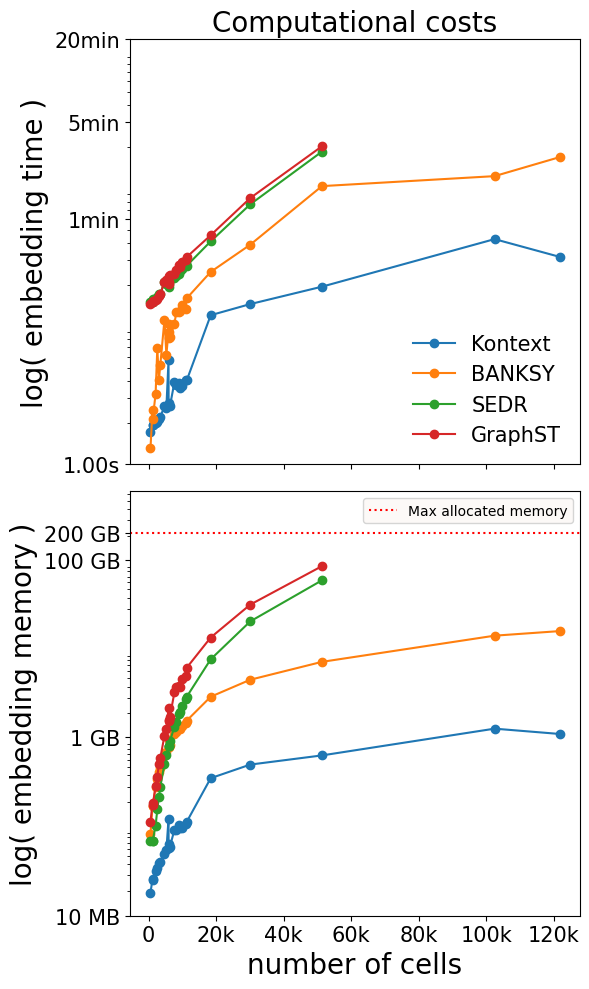

In [20]:
from kontext.utils import format_size,format_time

metrics = ['embedding_time', 'embedding_memory_b']
fig, axes = get_figs(len(metrics),6,5,vert=True)
for ax, met in zip(axes, metrics):
    print(met)
    plot_metric_vs_nobs(results_heatmap, STEREO, met, ax=ax,logy=True,logx=False)
axes[0].set_title('Computational costs',fontsize=20)
axes[1].set_title('',fontsize=20)
axes[0].set_ylabel('log( embedding time )',fontsize=20)
axes[1].set_ylabel('log( embedding memory )',fontsize=20)
axes[0].set_xlabel('',fontsize=15)
axes[1].set_xlabel('number of cells',fontsize=20)
axes[0].set_xticklabels([])

axes[1].set_xticklabels(['0','0','20k','40k','60k','80k','100k','120k'], rotation='horizontal', fontsize=15) 
axes[1].set_yticklabels(ax.get_yticklabels(), rotation='horizontal', fontsize=15) 

times = [1,60,60*5,20*60]
memory_sizes = [10*1024*1024,1024*1024*1024,1024**3*100,1024**3*100*2]

axes[0].set_yticks(times)
axes[0].set_yticklabels([format_time(time).split('-')[0] for time in times],fontsize=15)
axes[1].set_yticks(memory_sizes)
axes[1].set_yticklabels([format_size(memory).replace('.00','') for memory in memory_sizes],fontsize=15)
# axes[0].set_yticklabels([]ax.get_yticklabels(), rotation='horizontal', fontsize=15) 

axes[1].get_legend().remove()

line = axes[1].axhline(1024**3*100*2, linestyle=':', color='red')
axes[1].legend([line], ['Max allocated memory'])
axes[1].set_ylim(memory_sizes[0],1024**3*100*6)
fig.tight_layout()
# fig.savefig('kontext_project/figures/benchmark/benchmark_1b_time_memory.pdf')


## Supplementary figure S1 - Effect of alpha

### Run the method for each value of alpha

In [21]:
supp_results_alpha = {}
min_seed,max_seed = 0,100
seeds = range(min_seed,max_seed)
run_all = False # if True, run the benchmark for all the parameters of the loop, otherwise, runs only the parameters for which the result file is missing.  
annotations = ['ccf_region_name','tissue','cell_type']

total_torun = 0
total_done = 0
total_missing = 0
total = 0
nerr = 0

methods = {
'Kontext alpha=0.0':    {'additional_info':{'name':'alpha=0.0'},'matrix':'Kontext',     'embedding':{"sigma_e":1, "snn":20, 'alpha':0.0},'spatial_domains':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'image'}},
'Kontext alpha=0.1':    {'additional_info':{'name':'alpha=0.1'},'matrix':'Kontext',     'embedding':{"sigma_e":1, "snn":20, 'alpha':0.1},'spatial_domains':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'image'}},
'Kontext alpha=0.2':    {'additional_info':{'name':'alpha=0.2'},'matrix':'Kontext',     'embedding':{"sigma_e":1, "snn":20, 'alpha':0.2},'spatial_domains':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'image'}},
'Kontext alpha=0.3':    {'additional_info':{'name':'alpha=0.3'},'matrix':'Kontext',     'embedding':{"sigma_e":1, "snn":20, 'alpha':0.3},'spatial_domains':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'image'}},
'Kontext alpha=0.4':    {'additional_info':{'name':'alpha=0.4'},'matrix':'Kontext',     'embedding':{"sigma_e":1, "snn":20, 'alpha':0.4},'spatial_domains':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'image'}},
'Kontext alpha=0.5':    {'additional_info':{'name':'alpha=0.5'},'matrix':'Kontext',     'embedding':{"sigma_e":1, "snn":20, 'alpha':0.5},'spatial_domains':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'image'}},
'Kontext alpha=0.6':    {'additional_info':{'name':'alpha=0.6'},'matrix':'Kontext',     'embedding':{"sigma_e":1, "snn":20, 'alpha':0.6},'spatial_domains':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'image'}},
'Kontext alpha=0.7':    {'additional_info':{'name':'alpha=0.7'},'matrix':'Kontext',     'embedding':{"sigma_e":1, "snn":20, 'alpha':0.7},'spatial_domains':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'image'}},
'Kontext alpha=0.8':    {'additional_info':{'name':'alpha=0.8'},'matrix':'Kontext',     'embedding':{"sigma_e":1, "snn":20, 'alpha':0.8},'spatial_domains':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'image'}},
'Kontext alpha=0.9':    {'additional_info':{'name':'alpha=0.9'},'matrix':'Kontext',     'embedding':{"sigma_e":1, "snn":20, 'alpha':0.9},'spatial_domains':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'image'}},
'Kontext alpha=1.0':    {'additional_info':{'name':'alpha=1.0'},'matrix':'Kontext',     'embedding':{"sigma_e":1, "snn":20, 'alpha':1.0},'spatial_domains':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'image'}},

# 'BANKSY':{'matrix':'BANKSY','additional_info':{'name':'BANKSY'},'embedding':{'k_geom': 18, 'nbr_weight_decay': 'scaled_gaussian', 'm': 1, 'param_lambda': 0.4, 'n_comps': 50},'spatial_domains':{'clustering':'gmm','seed':0},'preprocessing':{'preprocessing':'BANKSY'}},
# 'SEDR':{'matrix':'SEDR','additional_info':{'name':'SEDR gmm'},'embedding':{'seed':0},'spatial_domains':{'clustering':'gmm','seed':0},'preprocessing':{'preprocessing':'SEDR'}},
# 'GraphST':{'matrix':'GraphST','additional_info':{'name':'GraphST gmm'},'embedding':{'seed':0},'spatial_domains':{'clustering':'gmm','seed':0},'preprocessing':{'preprocessing':None}},
}





for dataset,sample in BENCHMARK[:]:
    # print(dataset,sample)
    i = -1
    for annotation in annotations: 
        i+=1
        if dataset == 'MBA':
            data = {'dataset':dataset,'sample':sample,'annotation':annotation}
            results_str = f'{dataset}_{annotation}+{sample}'
            supp_results_alpha[results_str] = []
        else:
            if i == 0:
                data = {'dataset':dataset,'sample':sample}
                results_str = f'{dataset}+{sample}'
                supp_results_alpha[results_str] = []

        if dataset == 'MBA' or i == 0:
            for name,param0 in methods.items():  
                if dataset =='MBA':
                    print(results_str,dataset,sample,annotation,name,get_dataset_info()[dataset][sample]['n_obs'])
                else:
                    print(results_str,dataset,sample,name,get_dataset_info()[dataset][sample]['n_obs'])
                matrix = param0['matrix']

                if matrix == 'Kontext':
                    snn1000 =  param0['embedding']['snn']==1000

                matrix = param0['matrix'] 
                executor_params = {
                            'slurm_partition':'common' if matrix in ['Kontext','BANKSY'] else 'ml4ig_gpu',
                            'slurm_cpus_per_task':1,
                            'slurm_array_parallelism':100,
                            'slurm_mem':'100G' if snn1000 else ('100G' if dataset=='MOSTA' else '5G') if matrix in ['Kontext','BANKSY'] else ('200G' if dataset=='MOSTA' else '15G'),#get_needed_mem(dataset,sample,step='all'),
                            'timeout_min':600,
                            'slurm_job_name':f'{name}_{sample}_{annotation}' if dataset == 'MBA' else f'{name}_{sample}',
                            'slurm_srun_args':["--cpu-bind=none"],
                            'slurm_gres': None if matrix in ['Kontext','BANKSY'] else 'gpu:1',
                            }


                params_all = []
                params_done = []
                params_missing = []

                for seed in seeds:


                    param = {k:v.copy() if isinstance(v,dict) else v for k,v in param0.items()}
                    param['root'] = root
                    if matrix == 'Kontext':
                        if dataset == 'MBA':
                            param['preprocessing']['preprocessing'] = 'xenium'
                        else:
                            param['preprocessing']['preprocessing'] = 'large2svg'  

                    param['data'] = data
                    if 'seed' in param['embedding']:
                        param['embedding']['seed'] = seed
                    if 'seed' in param['spatial_domains']:
                        param['spatial_domains']['seed'] = seed
                    if dataset == 'MBA' and matrix == 'Kontext' and 'alpha' not in name:
                        param['embedding']['alpha'] = {'ccf_region_name':0,'tissue':0.1,'cell_type':1}[annotation]

                    signature = "_".join(f"{format_key(k)}{format_value(v)}" for k, v in {'matrix':param['matrix'],**param['preprocessing'],**param['embedding'],**param['spatial_domains']}.items() if v is not None and k!='additional_info')
                    path = benchmark_path(data,root=root)
                    p = path / f'{signature}.json'
                    params_all += [param]
                    
                    if not p.exists():
                        print(p)
                        params_missing += [param]
                    else:
                        params_done += [param]
                        try:
                            with open(p, "r") as f:
                                out = json.load(f)
                        except:
                            print(p)
                            nerr+=1

                        out['name'] = name
                        supp_results_alpha[results_str] += [out]





    #### Uncomment to run benchmark locally in the loop

                    # run_benchmark_wrapper(param)
                    # run_example(**param)

    ####        

                if dataset == 'MBA':
                    log_name = f"logs4/benchmark_{dataset}_{sample}_{annotation}/{name}/"
                else:
                    log_name = f"logs4/benchmark_{dataset}_{sample}/{matrix}/"

                executor = submitit.AutoExecutor(folder=log_name)
                executor.update_parameters(**executor_params ) 

                params_torun = params_all if run_all else params_missing
                n_torun = len(params_all) if run_all else len(params_missing)
                n_done = len(params_done)
                n_missing = len(params_missing)
                total_torun += n_torun
                total_done += n_done
                total_missing += n_missing
                if n_missing>0:
                    if dataset == 'MBA':
                        print(f'err{nerr} {dataset} {sample} {annotation} {matrix} to_run={n_torun} done={n_done} missing={n_missing} total_torun={total_torun} total_done={total_done} total_missing={total_missing}')
                    else:
                        print(f'err{nerr} {dataset} {sample} {matrix} to_run={n_torun} done={n_done} missing={n_missing} total_torun={total_torun} total_done={total_done} total_missing={total_missing}')
                # else:
                    # print(results_str,len(supp_results_alpha[results_str]))
    #### Uncomment to submit jobs with submitit

                # print(executor_params)
                # if len(params_torun)>0:
                #     jobs = executor.map_array(run_benchmark_wrapper,params_torun)

    #####
    

    print('####',dataset,sample,name,len(supp_results_alpha[results_str]))


###
###
###







ZESTA+zf3_1 ZESTA zf3_1 Kontext alpha=0.0 1167
ZESTA+zf3_1 ZESTA zf3_1 Kontext alpha=0.1 1167
ZESTA+zf3_1 ZESTA zf3_1 Kontext alpha=0.2 1167
ZESTA+zf3_1 ZESTA zf3_1 Kontext alpha=0.3 1167
ZESTA+zf3_1 ZESTA zf3_1 Kontext alpha=0.4 1167
ZESTA+zf3_1 ZESTA zf3_1 Kontext alpha=0.5 1167
ZESTA+zf3_1 ZESTA zf3_1 Kontext alpha=0.6 1167
ZESTA+zf3_1 ZESTA zf3_1 Kontext alpha=0.7 1167
ZESTA+zf3_1 ZESTA zf3_1 Kontext alpha=0.8 1167
ZESTA+zf3_1 ZESTA zf3_1 Kontext alpha=0.9 1167
ZESTA+zf3_1 ZESTA zf3_1 Kontext alpha=1.0 1167
#### ZESTA zf3_1 Kontext alpha=1.0 1100
ZESTA+zf5_10 ZESTA zf5_10 Kontext alpha=0.0 563
ZESTA+zf5_10 ZESTA zf5_10 Kontext alpha=0.1 563
ZESTA+zf5_10 ZESTA zf5_10 Kontext alpha=0.2 563
ZESTA+zf5_10 ZESTA zf5_10 Kontext alpha=0.3 563
ZESTA+zf5_10 ZESTA zf5_10 Kontext alpha=0.4 563
ZESTA+zf5_10 ZESTA zf5_10 Kontext alpha=0.5 563
ZESTA+zf5_10 ZESTA zf5_10 Kontext alpha=0.6 563
ZESTA+zf5_10 ZESTA zf5_10 Kontext alpha=0.7 563
ZESTA+zf5_10 ZESTA zf5_10 Kontext alpha=0.8 563
ZESTA+zf5_1

### Preprocess the results

In [22]:
results_heatmap_supp_alpha = {}

for dataset,sample in BENCHMARK:
    for annotation in annotations:
        if dataset == 'MBA':
            ds = f'{dataset}_{annotation}+{sample}'
        else:
            ds = f'{dataset}+{sample}'
        # print(ds)
        if ds not in supp_results_alpha:
            print(ds, 'not there')
            continue

        res = supp_results_alpha[ds]
        new_res_supp_alpha = []

        for run in res:
            i = run.copy()
            if i['matrix'] == 'Kontext':
                i['name'] = f"alpha = {i['alpha']}"
            # else:
            #     i['name'] = i['matrix']
            new_res_supp_alpha += [i]
        results_heatmap_supp_alpha[ds] = new_res_supp_alpha

### Plot supplementary figure S1 

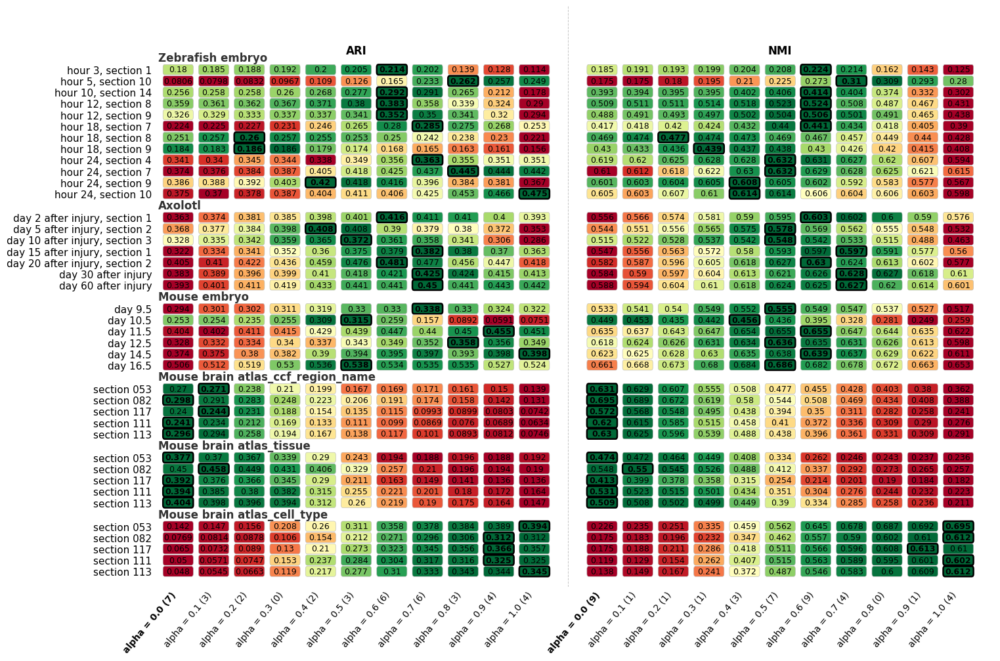

In [23]:
fig,axes,df2 = plot_sample_heatmap(results_heatmap_supp_alpha, metrics = ('ARI','NMI'
                                                                        # ,'HOM','COM'
                                                                        ), agg='mean', rect_width=0.85, rect_height=0.20,fontsize_ticks=10,fontsize_scores=9)

## Supplementary figure S2 - Ground truth STEREO

... storing 'sample' as categorical
... storing 'sample' as categorical
... storing 'sample' as categorical
... storing 'sample' as categorical
... storing 'sample' as categorical
... storing 'sample' as categorical
... storing 'sample' as categorical
... storing 'sample' as categorical
... storing 'sample' as categorical
... storing 'sample' as categorical
... storing 'sample' as categorical
... storing 'sample' as categorical
... storing 'sample' as categorical


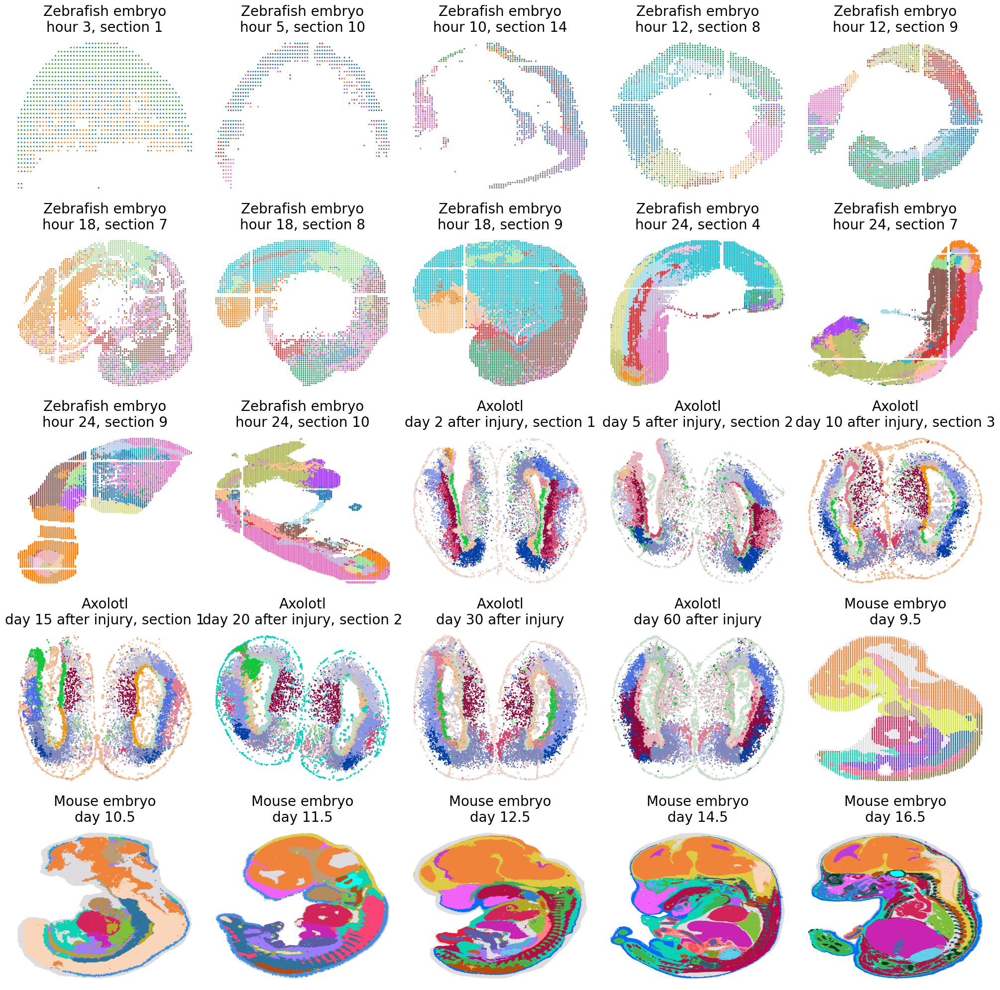

In [24]:
nrows = 5
ncols = 5
fig,axes = plt.subplots(nrows=nrows,ncols=ncols,figsize=(4*ncols,4*nrows))
i=-1
for dataset,sample in STEREO:
    data = {'dataset':dataset,'sample':sample,'annotation':annotation} if dataset == 'MBA' else {'dataset':dataset,'sample':sample} 
    dataset_name = readable_dataset_name(dataset)
    sample_name = readable_sample_name(sample)
    title =f'{dataset_name}\n{sample_name}'
    adata = load_adata(**data)


    i+=1
    ax = axes[i//5,i%5]
    space_plot(adata,'annotation',s=20,ax=ax)
    ax.get_legend().remove()
    ax.set_title(f'{title}',fontsize=20)
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.set_axis_off()
fig.tight_layout()

## Supplementary figure S3 - Ground truth MERFISH

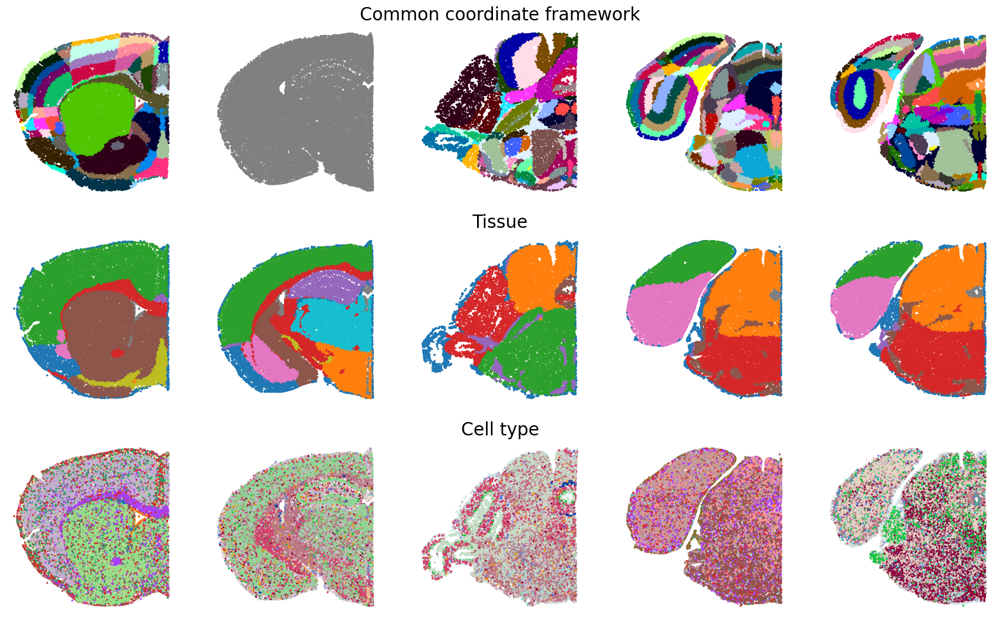

In [25]:
nrows = 3
ncols = 5
annotations = ['ccf_region_name','tissue','cell_type']
fig,axes = plt.subplots(nrows=nrows,ncols=ncols,figsize=(4*ncols,4*nrows))
i=-1
for annotation in annotations:
    for dataset,sample in MERFISH:
        
        data = {'dataset':dataset,'sample':sample,'annotation':annotation} if dataset == 'MBA' else {'dataset':dataset,'sample':sample} 
        ylabel =f'{dataset} {sample.split('_')[-1]}' if dataset == 'MBA' else f'{dataset} {sample.split('_')[0]}'
        adata = load_adata(**data)


        i+=1
        ax = axes[i//5,i%5]
        space_plot(adata,'annotation',s=20,ax=ax)
        ax.get_legend().remove()
        if i%5 == 2: 
            title = 'Common coordinate framework' if 'ccf' in annotation else \
                    'Tissue' if annotation == 'tissue' else 'Cell type'
        else : 
            title = ''
        ax.set_title(f'{title}',fontsize=20)
        ax.set_axis_off()
        if i//5 == 2:
            ax.set_xlabel(readable_sample_name(sample),fontsize=20)
        

## Supplementary figure S4 - Standard deviations

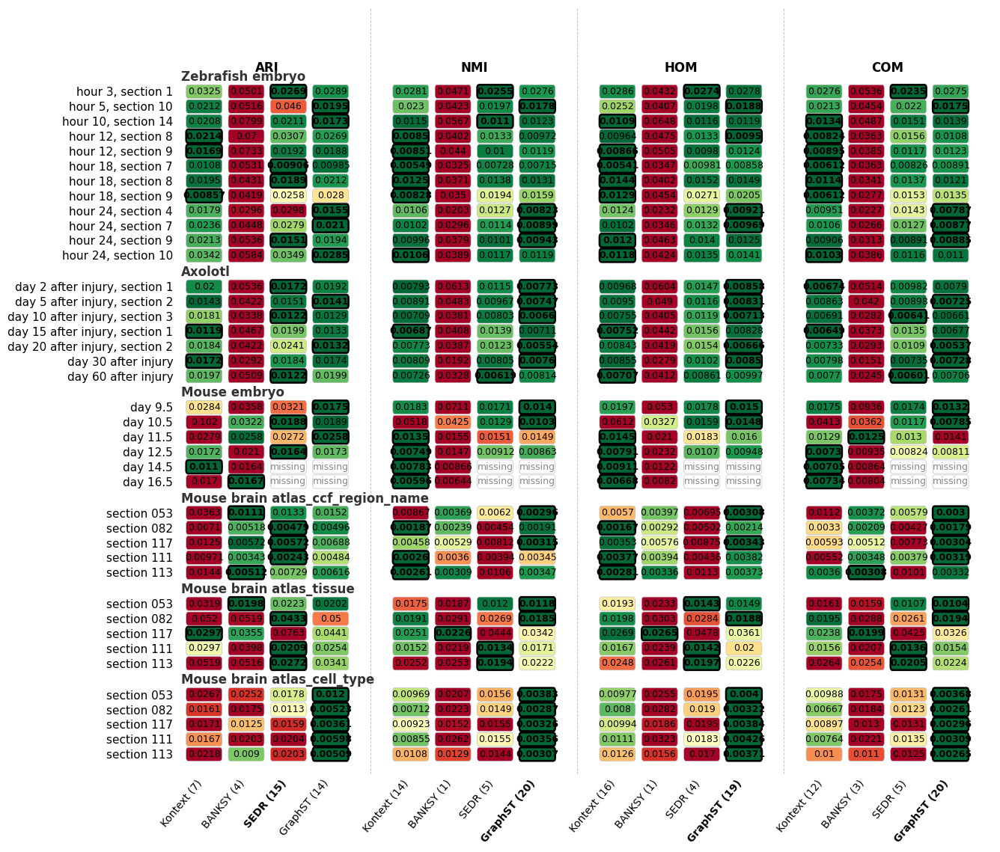

In [26]:
fig,axes,df2 = plot_sample_heatmap(results_heatmap, metrics = ('ARI','NMI','HOM','COM'),
                                   agg='std', rect_width=0.85, rect_height=0.20,fontsize_ticks=10,fontsize_scores=9,
                                   lower_better=('ARI','NMI','HOM','COM'),)
fig.tight_layout()

## Supplementary figure S5 - Mean scores per section

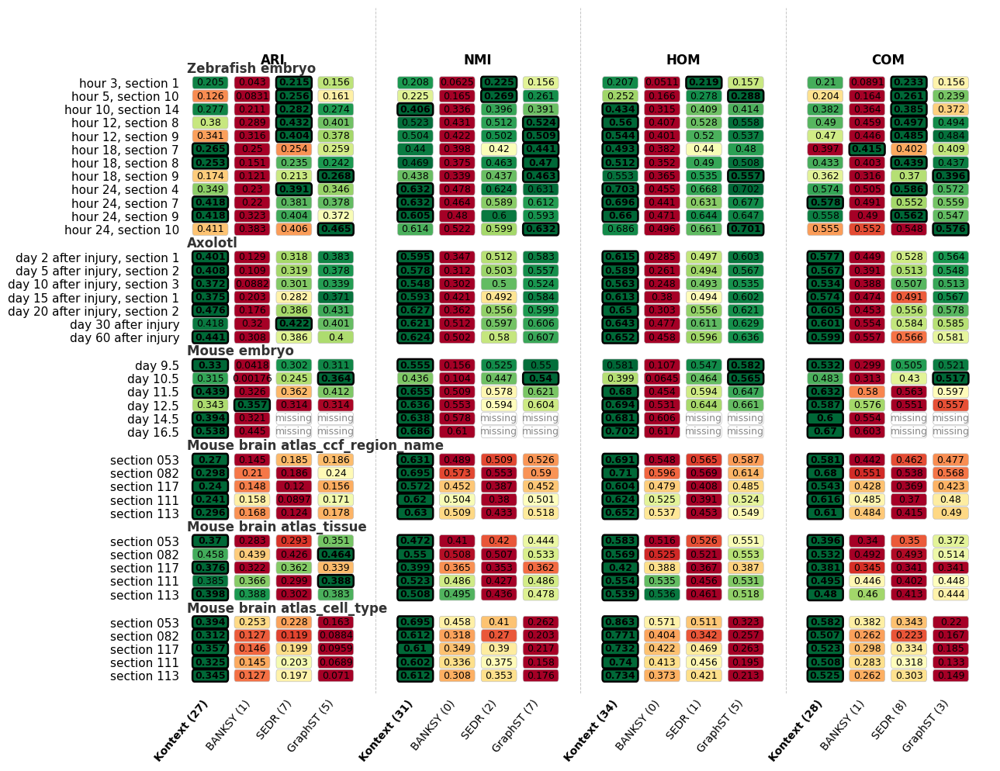

In [27]:
fig,axes,df2 = plot_sample_heatmap(results_heatmap, metrics = ('ARI','NMI' ,'HOM','COM'
                                                                          ), agg='mean', rect_width=0.85, rect_height=0.20,fontsize_ticks=10,fontsize_scores=9)


## Supplementary figure S17

In [28]:



min_seed,max_seed = 0,100
seeds = range(min_seed,max_seed)
run_all = False # if True, run the benchmark for all the parameters of the loop, otherwise, runs only the parameters for which the result file is missing.  


methods = {
'BANKSY l=0.0':{'matrix':'BANKSY','additional_info':{'name':'BANKSY l=0.0'},'embedding':{'k_geom': 18, 'nbr_weight_decay': 'scaled_gaussian', 'm': 1, 'param_lambda': 0.0, 'n_comps': 50},'spatial_domains':{'clustering':'gmm','seed':0},'preprocessing':{'preprocessing':'BANKSY'}},
'BANKSY l=0.1':{'matrix':'BANKSY','additional_info':{'name':'BANKSY l=0.1'},'embedding':{'k_geom': 18, 'nbr_weight_decay': 'scaled_gaussian', 'm': 1, 'param_lambda': 0.1, 'n_comps': 50},'spatial_domains':{'clustering':'gmm','seed':0},'preprocessing':{'preprocessing':'BANKSY'}},
'BANKSY l=0.2':{'matrix':'BANKSY','additional_info':{'name':'BANKSY l=0.2'},'embedding':{'k_geom': 18, 'nbr_weight_decay': 'scaled_gaussian', 'm': 1, 'param_lambda': 0.2, 'n_comps': 50},'spatial_domains':{'clustering':'gmm','seed':0},'preprocessing':{'preprocessing':'BANKSY'}},
'BANKSY l=0.3':{'matrix':'BANKSY','additional_info':{'name':'BANKSY l=0.3'},'embedding':{'k_geom': 18, 'nbr_weight_decay': 'scaled_gaussian', 'm': 1, 'param_lambda': 0.3, 'n_comps': 50},'spatial_domains':{'clustering':'gmm','seed':0},'preprocessing':{'preprocessing':'BANKSY'}},
'BANKSY l=0.4':{'matrix':'BANKSY','additional_info':{'name':'BANKSY l=0.4'},'embedding':{'k_geom': 18, 'nbr_weight_decay': 'scaled_gaussian', 'm': 1, 'param_lambda': 0.4, 'n_comps': 50},'spatial_domains':{'clustering':'gmm','seed':0},'preprocessing':{'preprocessing':'BANKSY'}},
'BANKSY l=0.5':{'matrix':'BANKSY','additional_info':{'name':'BANKSY l=0.5'},'embedding':{'k_geom': 18, 'nbr_weight_decay': 'scaled_gaussian', 'm': 1, 'param_lambda': 0.5, 'n_comps': 50},'spatial_domains':{'clustering':'gmm','seed':0},'preprocessing':{'preprocessing':'BANKSY'}},
'BANKSY l=0.6':{'matrix':'BANKSY','additional_info':{'name':'BANKSY l=0.6'},'embedding':{'k_geom': 18, 'nbr_weight_decay': 'scaled_gaussian', 'm': 1, 'param_lambda': 0.6, 'n_comps': 50},'spatial_domains':{'clustering':'gmm','seed':0},'preprocessing':{'preprocessing':'BANKSY'}},
'BANKSY l=0.7':{'matrix':'BANKSY','additional_info':{'name':'BANKSY l=0.7'},'embedding':{'k_geom': 18, 'nbr_weight_decay': 'scaled_gaussian', 'm': 1, 'param_lambda': 0.7, 'n_comps': 50},'spatial_domains':{'clustering':'gmm','seed':0},'preprocessing':{'preprocessing':'BANKSY'}},
'BANKSY l=0.8':{'matrix':'BANKSY','additional_info':{'name':'BANKSY l=0.8'},'embedding':{'k_geom': 18, 'nbr_weight_decay': 'scaled_gaussian', 'm': 1, 'param_lambda': 0.8, 'n_comps': 50},'spatial_domains':{'clustering':'gmm','seed':0},'preprocessing':{'preprocessing':'BANKSY'}},
'BANKSY l=0.9':{'matrix':'BANKSY','additional_info':{'name':'BANKSY l=0.9'},'embedding':{'k_geom': 18, 'nbr_weight_decay': 'scaled_gaussian', 'm': 1, 'param_lambda': 0.9, 'n_comps': 50},'spatial_domains':{'clustering':'gmm','seed':0},'preprocessing':{'preprocessing':'BANKSY'}},
'BANKSY l=1':{'matrix':'BANKSY','additional_info':{'name':'BANKSY l=1'},'embedding':{'k_geom': 18, 'nbr_weight_decay': 'scaled_gaussian', 'm': 1, 'param_lambda': 1, 'n_comps': 50},'spatial_domains':{'clustering':'gmm','seed':0},'preprocessing':{'preprocessing':'BANKSY'}},
'Kontext':{'matrix':'Kontext','additional_info':{'name':'Kontext'},'embedding':{"sigma_e":1, "snn":20, 'alpha':1/2},'spatial_domains':{'clustering':'gmm','seed':0},'preprocessing':{'preprocessing':'large2svg'}},
}


total_torun = 0
total_done = 0
total_missing = 0
total = 0
results_banksy = {}

for dataset,sample in BENCHMARK[:]:
    print(dataset,sample,get_dataset_info()[dataset][sample]['n_obs'])
    i=-1
    for annotation in  annotations:
        i+=1
        if dataset == 'MBA':
            print(dataset,sample,annotation)
            data = {'dataset':dataset,'sample':sample,'annotation':annotation}
            results_str = f'{dataset}_{annotation}+{sample}'
            results_banksy[results_str] = []

        elif i == 0:
            data = {'dataset':dataset,'sample':sample}
            results_str = f'{dataset}_+{sample}'
            results_banksy[results_str] = []

        if dataset == 'MBA' or i==0:
            for name,param0 in methods.items():    
                matrix = param0['matrix']

                executor_params = {
                            'slurm_partition':'common' if matrix in ['Kontext','BANKSY'] else 'ml4ig_gpu',
                            'slurm_cpus_per_task':1,
                            'slurm_array_parallelism':100,
                            'slurm_mem':('50G' if dataset=='MOSTA' else '5G') if matrix in ['Kontext','BANKSY'] else ('100G' if dataset=='MOSTA' else '5G'),#get_needed_mem(dataset,sample,step='all'),
                            'timeout_min':600,
                            'slurm_job_name':f'{name}_{sample}',
                            'slurm_srun_args':["--cpu-bind=none",'--nice=19'],
                            'slurm_gres': None if matrix in ['Kontext','BANKSY'] else 'gpu:1',
                            }

                params_all = []
                params_done = []
                params_missing = []


                for seed in seeds:


                    param = {k:v.copy() if isinstance(v,dict) else v for k,v in param0.items()}
                    param['data'] = data
                    param['root'] = root
                    if 'seed' in param['embedding']:
                        param['embedding']['seed'] = seed
                    if 'seed' in param['spatial_domains']:
                        param['spatial_domains']['seed'] = seed
                    if matrix == 'Kontext':
                        param['preprocessing']['preprocessing'] = 'xenium' if dataset == 'MBA' else 'large2svg'
                        if dataset == 'MBA':
                            param['embedding']['alpha'] = {'ccf_region_name':0,'tissue':0.1,'cell_type':1.0}[annotation]
                            
                    signature = "_".join(f"{format_key(k)}{format_value(v)}" for k, v in {'matrix':param['matrix'],**param['preprocessing'],**param['embedding'],**param['spatial_domains']}.items() if v is not None and k!='additional_info')
                    path = benchmark_path(data,root=root)
                    p = path / f'{signature}.json'

                    params_all += [param]
                    
                    if not p.exists():
                        params_missing += [param]
                        print(p)


### local 
                        # run_benchmark_wrapper(param)
###

                    else:
                        params_done += [param]
                        with open(p, "r") as f:
                            out = json.load(f)
                        results_banksy[results_str] += [out]




                if dataset == 'MBA':
                    executor = submitit.AutoExecutor(folder=f"logs/benchmark_{dataset}_{sample}_{annotation}/{matrix}/")
                else:
                    executor = submitit.AutoExecutor(folder=f"logs/benchmark_{dataset}_{sample}/{matrix}/")
                executor.update_parameters(**executor_params ) 

                params_torun = params_all if run_all else params_missing
                n_torun = len(params_all) if run_all else len(params_missing)
                n_done = len(params_done)
                n_missing = len(params_missing)
                total_torun += n_torun
                total_done += n_done
                total_missing += n_missing

                print(f'{dataset} {sample} {name} to_run={n_torun} done={n_done} missing={n_missing} total_torun={total_torun} total_done={total_done} total_missing={total_missing}')
### submitit 
                # # print(executor_params)
                # if len(params_torun)>0:
                #     jobs = executor.map_array(run_benchmark_wrapper,params_torun)
###

print(results_banksy[results_str])


ZESTA zf3_1 1167
ZESTA zf3_1 BANKSY l=0.0 to_run=0 done=100 missing=0 total_torun=0 total_done=100 total_missing=0
ZESTA zf3_1 BANKSY l=0.1 to_run=0 done=100 missing=0 total_torun=0 total_done=200 total_missing=0
ZESTA zf3_1 BANKSY l=0.2 to_run=0 done=100 missing=0 total_torun=0 total_done=300 total_missing=0
ZESTA zf3_1 BANKSY l=0.3 to_run=0 done=100 missing=0 total_torun=0 total_done=400 total_missing=0
ZESTA zf3_1 BANKSY l=0.4 to_run=0 done=100 missing=0 total_torun=0 total_done=500 total_missing=0
ZESTA zf3_1 BANKSY l=0.5 to_run=0 done=100 missing=0 total_torun=0 total_done=600 total_missing=0
ZESTA zf3_1 BANKSY l=0.6 to_run=0 done=100 missing=0 total_torun=0 total_done=700 total_missing=0
ZESTA zf3_1 BANKSY l=0.7 to_run=0 done=100 missing=0 total_torun=0 total_done=800 total_missing=0
ZESTA zf3_1 BANKSY l=0.8 to_run=0 done=100 missing=0 total_torun=0 total_done=900 total_missing=0
ZESTA zf3_1 BANKSY l=0.9 to_run=0 done=100 missing=0 total_torun=0 total_done=1000 total_missing=0
ZE

ARTISTA 10DPI_3 Kontext to_run=0 done=100 missing=0 total_torun=0 total_done=18000 total_missing=0
ARTISTA 15DPI_1 8996
ARTISTA 15DPI_1 BANKSY l=0.0 to_run=0 done=100 missing=0 total_torun=0 total_done=18100 total_missing=0
ARTISTA 15DPI_1 BANKSY l=0.1 to_run=0 done=100 missing=0 total_torun=0 total_done=18200 total_missing=0
ARTISTA 15DPI_1 BANKSY l=0.2 to_run=0 done=100 missing=0 total_torun=0 total_done=18300 total_missing=0
ARTISTA 15DPI_1 BANKSY l=0.3 to_run=0 done=100 missing=0 total_torun=0 total_done=18400 total_missing=0
ARTISTA 15DPI_1 BANKSY l=0.4 to_run=0 done=100 missing=0 total_torun=0 total_done=18500 total_missing=0
ARTISTA 15DPI_1 BANKSY l=0.5 to_run=0 done=100 missing=0 total_torun=0 total_done=18600 total_missing=0
ARTISTA 15DPI_1 BANKSY l=0.6 to_run=0 done=100 missing=0 total_torun=0 total_done=18700 total_missing=0
ARTISTA 15DPI_1 BANKSY l=0.7 to_run=0 done=100 missing=0 total_torun=0 total_done=18800 total_missing=0
ARTISTA 15DPI_1 BANKSY l=0.8 to_run=0 done=100 m

In [29]:
banksy_with_kontext = {}
banksy_without_kontext = {}

for k,v in results_banksy.items():
    res_w = []
    res_wo = []
    for i in v:
        # print(i['name'],i['dataset'],i['sample'],i['annotation'],i['ARI'])
        if 'BANKSY' in i['name']:
            i['name'] = f"BANKSY lambda={i['param_lambda']}"
            res_w += [i]
            res_wo += [i]
        if i['matrix']=='Kontext':
            i['name'] = 'Kontext'
            res_w += [i]
            print(i['dataset'],i['sample'],i['annotation'],i['alpha'],i['signature'])
    banksy_with_kontext[k] = res_w
    banksy_without_kontext[k] = res_wo


ZESTA zf3_1 tissue 0.5 Kontext_large2svg_se1_snn20_a0.50_gmm_seed0
ZESTA zf3_1 tissue 0.5 Kontext_large2svg_se1_snn20_a0.50_gmm_seed1
ZESTA zf3_1 tissue 0.5 Kontext_large2svg_se1_snn20_a0.50_gmm_seed2
ZESTA zf3_1 tissue 0.5 Kontext_large2svg_se1_snn20_a0.50_gmm_seed3
ZESTA zf3_1 tissue 0.5 Kontext_large2svg_se1_snn20_a0.50_gmm_seed4
ZESTA zf3_1 tissue 0.5 Kontext_large2svg_se1_snn20_a0.50_gmm_seed5
ZESTA zf3_1 tissue 0.5 Kontext_large2svg_se1_snn20_a0.50_gmm_seed6
ZESTA zf3_1 tissue 0.5 Kontext_large2svg_se1_snn20_a0.50_gmm_seed7
ZESTA zf3_1 tissue 0.5 Kontext_large2svg_se1_snn20_a0.50_gmm_seed8
ZESTA zf3_1 tissue 0.5 Kontext_large2svg_se1_snn20_a0.50_gmm_seed9
ZESTA zf3_1 tissue 0.5 Kontext_large2svg_se1_snn20_a0.50_gmm_seed10
ZESTA zf3_1 tissue 0.5 Kontext_large2svg_se1_snn20_a0.50_gmm_seed11
ZESTA zf3_1 tissue 0.5 Kontext_large2svg_se1_snn20_a0.50_gmm_seed12
ZESTA zf3_1 tissue 0.5 Kontext_large2svg_se1_snn20_a0.50_gmm_seed13
ZESTA zf3_1 tissue 0.5 Kontext_large2svg_se1_snn20_a0.50_g

(<Figure size 1648.8x1149 with 1 Axes>,
 <Axes: >,
                                    BANKSY lambda=0.0 | ARI  \
 ZESTA_+zf3_1                                      0.004820   
 ZESTA_+zf5_10                                     0.093517   
 ZESTA_+zf10_14                                    0.050835   
 ZESTA_+zf12_8                                     0.038967   
 ZESTA_+zf12_9                                     0.049432   
 ZESTA_+zf18_7                                     0.029671   
 ZESTA_+zf18_8                                     0.036588   
 ZESTA_+zf18_9                                     0.038454   
 ZESTA_+zf24_4                                     0.121699   
 ZESTA_+zf24_7                                     0.105358   
 ZESTA_+zf24_9                                     0.159196   
 ZESTA_+zf24_10                                    0.133605   
 ARTISTA_+2DPI_1                                   0.033340   
 ARTISTA_+5DPI_2                                   0.033380   
 ART

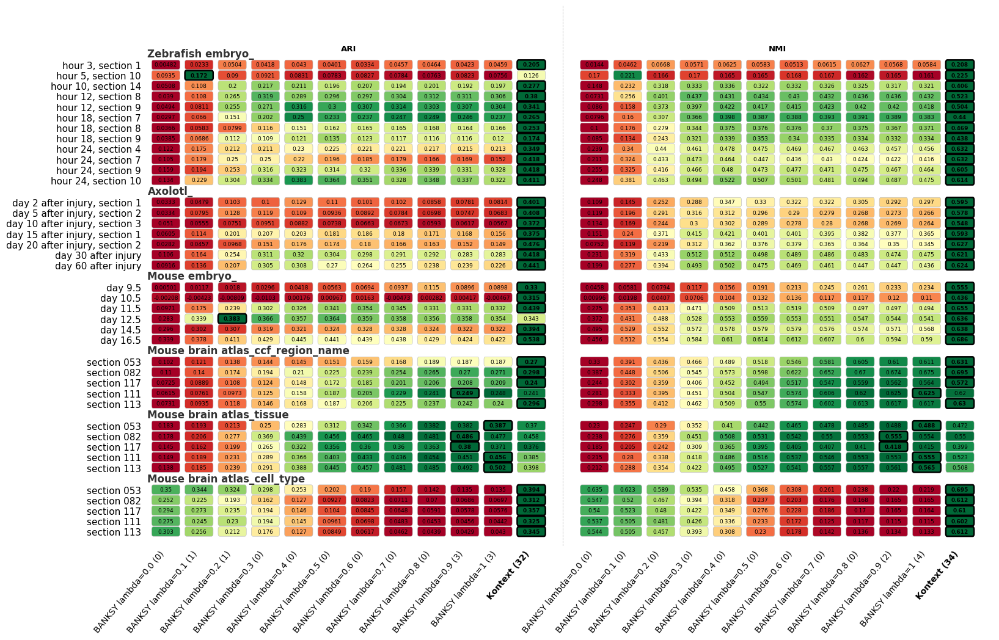

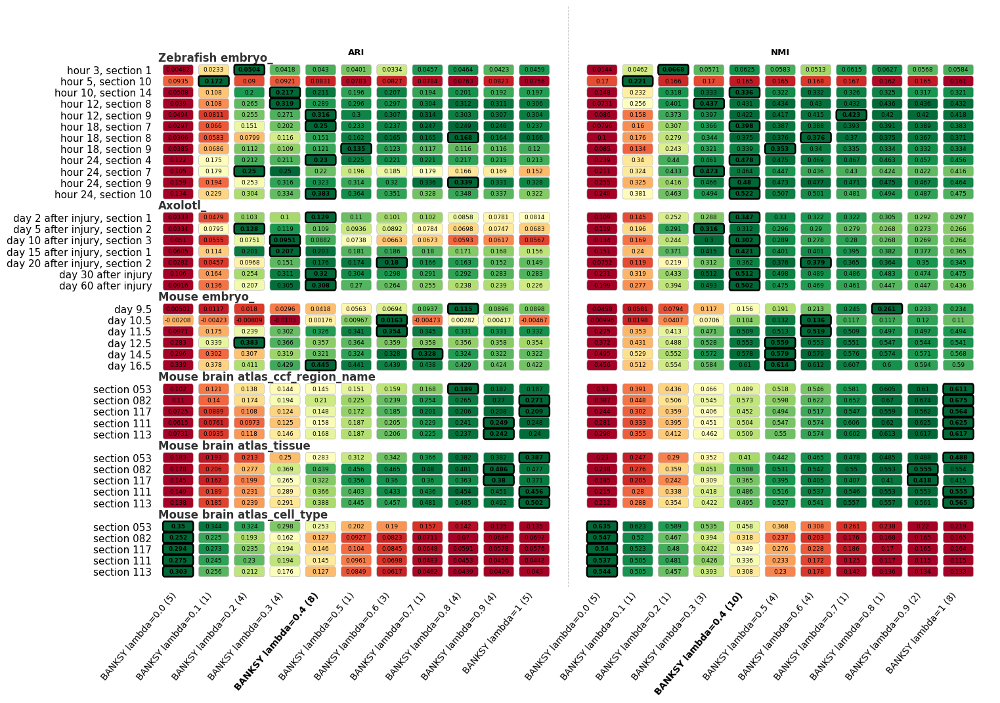

In [30]:
plot_sample_heatmap(banksy_with_kontext, metrics = ('ARI','NMI'), agg='mean', rect_width=0.85, rect_height=0.20,perfect = False)
plot_sample_heatmap(banksy_without_kontext, metrics = ('ARI','NMI'), agg='mean', rect_width=0.85, rect_height=0.20,perfect = False)

## supplementary figure S18

In [31]:

results_fixed_alpha = {}
for dataset,sample in BENCHMARK:
    for annotation in annotations:
        if dataset == 'MBA':
            ds = f'{dataset}_{annotation}+{sample}'
        else:
            ds = f'{dataset}+{sample}'
        if ds not in results:
            continue

        res = results[ds]
        new_res_fixed_alpha = []

        names = {}
        for run in res:
            i = run.copy()
            for method in ['BANKSY','SEDR','GraphST']:
                if method == i['matrix']:
                    i['name'] = method
                    if i['name'] not in names:
                        print(i['name'],end=' ')
                        names[i['name']] = 0
                    else:
                        names[i['name']]+=1            
                    new_res_fixed_alpha += [i]


            if i['matrix'] == 'Kontext':
                i['name'] = 'Kontext'
                if i['alpha'] == 0.5 and i['snn']==20 and i['sigma_e']==1:
                    # print(i)
                    if i['name'] not in names:
                        print(i['name'],end=' ')
                        names[i['name']] = 0
                    else:
                        names[i['name']]+=1            
                    new_res_fixed_alpha += [i]


        print(names)
        print(ds,len(new_res_fixed_alpha))
        names = {}
        for i in new_res_fixed_alpha:
            if i['matrix'] not in names:
                names[i['matrix']] = 0
            else:
                names[i['matrix']] +=1
        print(names)
        # for i in new_res_fixed_alpha:
        #     print(i['alpha'])
        results_fixed_alpha[ds] = new_res_fixed_alpha


Kontext BANKSY SEDR GraphST {'Kontext': 99, 'BANKSY': 99, 'SEDR': 99, 'GraphST': 99}
ZESTA+zf3_1 400
{'Kontext': 99, 'BANKSY': 99, 'SEDR': 99, 'GraphST': 99}
Kontext BANKSY SEDR GraphST {'Kontext': 99, 'BANKSY': 99, 'SEDR': 99, 'GraphST': 99}
ZESTA+zf3_1 400
{'Kontext': 99, 'BANKSY': 99, 'SEDR': 99, 'GraphST': 99}
Kontext BANKSY SEDR GraphST {'Kontext': 99, 'BANKSY': 99, 'SEDR': 99, 'GraphST': 99}
ZESTA+zf3_1 400
{'Kontext': 99, 'BANKSY': 99, 'SEDR': 99, 'GraphST': 99}
Kontext BANKSY SEDR GraphST {'Kontext': 99, 'BANKSY': 99, 'SEDR': 99, 'GraphST': 99}
ZESTA+zf5_10 400
{'Kontext': 99, 'BANKSY': 99, 'SEDR': 99, 'GraphST': 99}
Kontext BANKSY SEDR GraphST {'Kontext': 99, 'BANKSY': 99, 'SEDR': 99, 'GraphST': 99}
ZESTA+zf5_10 400
{'Kontext': 99, 'BANKSY': 99, 'SEDR': 99, 'GraphST': 99}
Kontext BANKSY SEDR GraphST {'Kontext': 99, 'BANKSY': 99, 'SEDR': 99, 'GraphST': 99}
ZESTA+zf5_10 400
{'Kontext': 99, 'BANKSY': 99, 'SEDR': 99, 'GraphST': 99}
Kontext BANKSY SEDR GraphST {'Kontext': 99, 'BANK

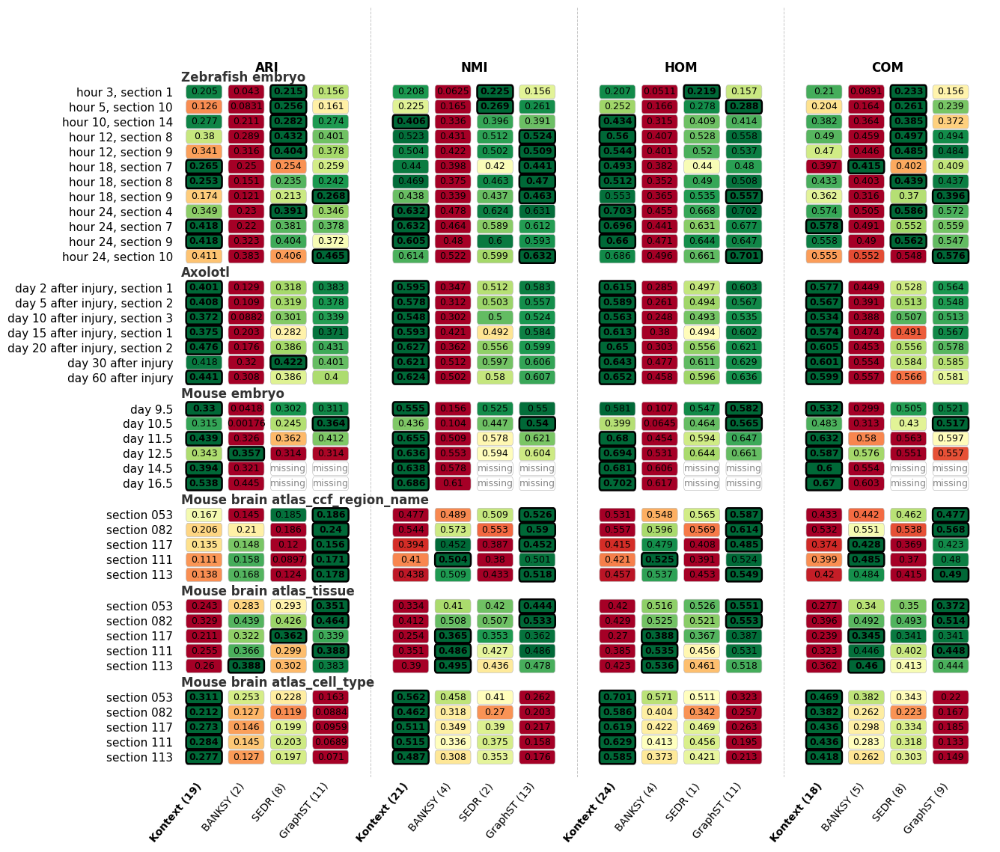

In [32]:

fig,axes,df2 = plot_sample_heatmap(results_fixed_alpha, metrics = ('ARI','NMI','HOM','COM'),
                                   agg='mean', rect_width=0.85, rect_height=0.20,fontsize_ticks=10,fontsize_scores=9,perfect =True)
fig.tight_layout()

## Supplementary figures S19

In [33]:
supp_results_snn = {}
min_seed,max_seed = 0,100
seeds = range(min_seed,max_seed)
run_all = False # if True, run the benchmark for all the parameters of the loop, otherwise, runs only the parameters for which the result file is missing.  
annotations = ['ccf_region_name','tissue','cell_type']

total_torun = 0
total_done = 0
total_missing = 0
total = 0

methods = {
'Kontext snn=5':    {'additional_info':{'name':'snn=5'},'matrix':'Kontext',        'embedding':{"sigma_e":1, "snn":5, 'alpha':0.5},'spatial_domains':{'clustering':'gmm','seed':0}      ,'preprocessing':{'preprocessing':'image'}},
'Kontext snn=20':   {'additional_info':{'name':'snn=20'},'matrix':'Kontext',       'embedding':{"sigma_e":1, "snn":20, 'alpha':0.5},'spatial_domains':{'clustering':'gmm','seed':0}     ,'preprocessing':{'preprocessing':'image'}},
'Kontext snn=100':  {'additional_info':{'name':'snn=100'},'matrix':'Kontext',      'embedding':{"sigma_e":1, "snn":100, 'alpha':0.5},'spatial_domains':{'clustering':'gmm','seed':0}    ,'preprocessing':{'preprocessing':'image'}},
'Kontext snn=300':  {'additional_info':{'name':'snn=300'},'matrix':'Kontext',      'embedding':{"sigma_e":1, "snn":300, 'alpha':0.5},'spatial_domains':{'clustering':'gmm','seed':0}    ,'preprocessing':{'preprocessing':'image'}},
'Kontext snn=1000': {'additional_info':{'name':'snn=1000'},'matrix':'Kontext',     'embedding':{"sigma_e":1, "snn":1000, 'alpha':0.5},'spatial_domains':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'image'}},
'BANKSY':{'matrix':'BANKSY','additional_info':{'name':'BANKSY'},'embedding':{'k_geom': 18, 'nbr_weight_decay': 'scaled_gaussian', 'm': 1, 'param_lambda': 0.4, 'n_comps': 50},'spatial_domains':{'clustering':'gmm','seed':0},'preprocessing':{'preprocessing':'BANKSY'}},
'SEDR':{'matrix':'SEDR','additional_info':{'name':'SEDR gmm'},'embedding':{'seed':0},'spatial_domains':{'clustering':'gmm','seed':0},'preprocessing':{'preprocessing':'SEDR'}},
'GraphST':{'matrix':'GraphST','additional_info':{'name':'GraphST gmm'},'embedding':{'seed':0},'spatial_domains':{'clustering':'gmm','seed':0},'preprocessing':{'preprocessing':None}},
}



for dataset,sample in BENCHMARK[:]:
    i = -1
    for annotation in annotations: 
        i+=1
        if dataset == 'MBA':
            data = {'dataset':dataset,'sample':sample,'annotation':annotation}
            results_str = f'{dataset}_{annotation}+{sample}'
            supp_results_snn[results_str] = []
        else:
            if i == 0:
                data = {'dataset':dataset,'sample':sample}
                results_str = f'{dataset}+{sample}'
                supp_results_snn[results_str] = []

        if dataset == 'MBA' or i == 0:
            for name,param0 in methods.items():  
                if dataset =='MBA':
                    print(results_str,dataset,sample,annotation,name,get_dataset_info()[dataset][sample]['n_obs'])
                else:
                    print(results_str,dataset,sample,name,get_dataset_info()[dataset][sample]['n_obs'])
                matrix = param0['matrix']

                if matrix == 'Kontext':
                    snn1000 =  param0['embedding']['snn']==1000

                matrix = param0['matrix'] 
                executor_params = {
                            'slurm_partition':'common' if matrix in ['Kontext','BANKSY'] else 'ml4ig_gpu',
                            'slurm_cpus_per_task':1,
                            'slurm_array_parallelism':100,
                            'slurm_mem':'100G' if snn1000 else ('100G' if dataset=='MOSTA' else '5G') if matrix in ['Kontext','BANKSY'] else ('200G' if dataset=='MOSTA' else '15G'),#get_needed_mem(dataset,sample,step='all'),
                            'timeout_min':600,
                            'slurm_job_name':f'{name}_{sample}_{annotation}' if dataset == 'MBA' else f'{name}_{sample}',
                            'slurm_srun_args':["--cpu-bind=none"],
                            'slurm_gres': None if matrix in ['Kontext','BANKSY'] else 'gpu:1',
                            }


                params_all = []
                params_done = []
                params_missing = []

                for seed in seeds:


                    param = {k:v.copy() if isinstance(v,dict) else v for k,v in param0.items()}
                    param['root'] = root
                    if matrix == 'Kontext':
                        if dataset == 'MBA':
                            param['preprocessing']['preprocessing'] = 'xenium'
                        else:
                            param['preprocessing']['preprocessing'] = 'large2svg'  

                    param['data'] = data
                    if 'seed' in param['embedding']:
                        param['embedding']['seed'] = seed
                    if 'seed' in param['spatial_domains']:
                        param['spatial_domains']['seed'] = seed
                    if dataset == 'MBA' and matrix == 'Kontext' and 'alpha' not in name:
                        param['embedding']['alpha'] = {'ccf_region_name':0,'tissue':0.1,'cell_type':1}[annotation]

                    signature = "_".join(f"{format_key(k)}{format_value(v)}" for k, v in {'matrix':param['matrix'],**param['preprocessing'],**param['embedding'],**param['spatial_domains']}.items() if v is not None and k!='additional_info')
                    path = benchmark_path(data,root=root)
                    p = path / f'{signature}.json'
                    params_all += [param]
                    
                    if not p.exists():
                        # print(p)
                        params_missing += [param]
                    else:
                        params_done += [param]
                        try:
                            with open(p, "r") as f:
                                out = json.load(f)
                        except:
                            print(p)
                            nerr+=1

                        out['name'] = name
                        supp_results_snn[results_str] += [out]





    #### Uncomment to run benchmark locally in the loop

                    # run_benchmark_wrapper(param)
                    # run_example(**param)

    ####        

                if dataset == 'MBA':
                    log_name = f"logs4/benchmark_{dataset}_{sample}_{annotation}/{name}/"
                else:
                    log_name = f"logs4/benchmark_{dataset}_{sample}/{matrix}/"

                executor = submitit.AutoExecutor(folder=log_name)
                executor.update_parameters(**executor_params ) 

                params_torun = params_all if run_all else params_missing
                n_torun = len(params_all) if run_all else len(params_missing)
                n_done = len(params_done)
                n_missing = len(params_missing)
                total_torun += n_torun
                total_done += n_done
                total_missing += n_missing
                if n_missing>0:
                    if dataset == 'MBA':
                        print(f'err{nerr} {dataset} {sample} {annotation} {matrix} to_run={n_torun} done={n_done} missing={n_missing} total_torun={total_torun} total_done={total_done} total_missing={total_missing}')
                    else:
                        print(f'err{nerr} {dataset} {sample} {matrix} to_run={n_torun} done={n_done} missing={n_missing} total_torun={total_torun} total_done={total_done} total_missing={total_missing}')

    #### Uncomment to submit jobs with submitit

                # print(executor_params)
                # if len(params_torun)>0:
                #     jobs = executor.map_array(run_benchmark_wrapper,params_torun)
    #####
    

    print('####',dataset,sample,name,len(supp_results_snn[results_str]))





ZESTA+zf3_1 ZESTA zf3_1 Kontext snn=5 1167
ZESTA+zf3_1 ZESTA zf3_1 Kontext snn=20 1167
ZESTA+zf3_1 ZESTA zf3_1 Kontext snn=100 1167
ZESTA+zf3_1 ZESTA zf3_1 Kontext snn=300 1167
ZESTA+zf3_1 ZESTA zf3_1 Kontext snn=1000 1167
ZESTA+zf3_1 ZESTA zf3_1 BANKSY 1167
ZESTA+zf3_1 ZESTA zf3_1 SEDR 1167
ZESTA+zf3_1 ZESTA zf3_1 GraphST 1167
#### ZESTA zf3_1 GraphST 800
ZESTA+zf5_10 ZESTA zf5_10 Kontext snn=5 563
ZESTA+zf5_10 ZESTA zf5_10 Kontext snn=20 563
ZESTA+zf5_10 ZESTA zf5_10 Kontext snn=100 563
ZESTA+zf5_10 ZESTA zf5_10 Kontext snn=300 563
ZESTA+zf5_10 ZESTA zf5_10 Kontext snn=1000 563
err0 ZESTA zf5_10 Kontext to_run=100 done=0 missing=100 total_torun=100 total_done=1200 total_missing=100
ZESTA+zf5_10 ZESTA zf5_10 BANKSY 563
ZESTA+zf5_10 ZESTA zf5_10 SEDR 563
ZESTA+zf5_10 ZESTA zf5_10 GraphST 563
#### ZESTA zf5_10 GraphST 700
ZESTA+zf10_14 ZESTA zf10_14 Kontext snn=5 1231
ZESTA+zf10_14 ZESTA zf10_14 Kontext snn=20 1231
ZESTA+zf10_14 ZESTA zf10_14 Kontext snn=100 1231
ZESTA+zf10_14 ZESTA zf1

MBA_cell_type+C57BL6J_1_117 MBA C57BL6J_1_117 cell_type BANKSY 22862
MBA_cell_type+C57BL6J_1_117 MBA C57BL6J_1_117 cell_type SEDR 22862
MBA_cell_type+C57BL6J_1_117 MBA C57BL6J_1_117 cell_type GraphST 22862
#### MBA C57BL6J_1_117 GraphST 800
MBA_ccf_region_name+C57BL6J_1_111 MBA C57BL6J_1_111 ccf_region_name Kontext snn=5 35171
MBA_ccf_region_name+C57BL6J_1_111 MBA C57BL6J_1_111 ccf_region_name Kontext snn=20 35171
MBA_ccf_region_name+C57BL6J_1_111 MBA C57BL6J_1_111 ccf_region_name Kontext snn=100 35171
MBA_ccf_region_name+C57BL6J_1_111 MBA C57BL6J_1_111 ccf_region_name Kontext snn=300 35171
MBA_ccf_region_name+C57BL6J_1_111 MBA C57BL6J_1_111 ccf_region_name Kontext snn=1000 35171
MBA_ccf_region_name+C57BL6J_1_111 MBA C57BL6J_1_111 ccf_region_name BANKSY 35171
MBA_ccf_region_name+C57BL6J_1_111 MBA C57BL6J_1_111 ccf_region_name SEDR 35171
MBA_ccf_region_name+C57BL6J_1_111 MBA C57BL6J_1_111 ccf_region_name GraphST 35171
MBA_tissue+C57BL6J_1_111 MBA C57BL6J_1_111 tissue Kontext snn=5 35171

In [34]:

results_heatmap_supp_snn = {}
results_heatmap_supp_snn_time = {}

for dataset,sample in BENCHMARK:
    for annotation in annotations:
        if dataset == 'MBA':
            ds = f'{dataset}_{annotation}+{sample}'
        else:
            ds = f'{dataset}+{sample}'
        if ds not in supp_results_snn:
            continue

        res = supp_results_snn[ds]
        new_res_supp_sigma = []
        new_res_supp_snn   = []
        new_res_supp_snn_time   = []
        new_res_supp_alpha = []

        for run in res:
            i = run.copy()
            i['dataset'] = f'{dataset} {annotation}'.replace('MBA_','MBA ')
            i['dataset'] = readable_dataset_name(i['dataset'])
            i['sample'] = readable_sample_name(i['sample'])
            i['name'] = i['name'].replace('Kontext ','')

            if 'snn' in i['name']:
                # i['name'] = i['name'].replace('snn',r'\ell')
                new_res_supp_snn   += [i]
                
                if sample == 'E16.5_E1S1':
                    new_res_supp_snn_time += [i]
            if i['matrix'] != 'Kontext':
                new_res_supp_snn   += [i]


        results_heatmap_supp_snn[ds] = new_res_supp_snn
        results_heatmap_supp_snn_time[ds] = new_res_supp_snn_time


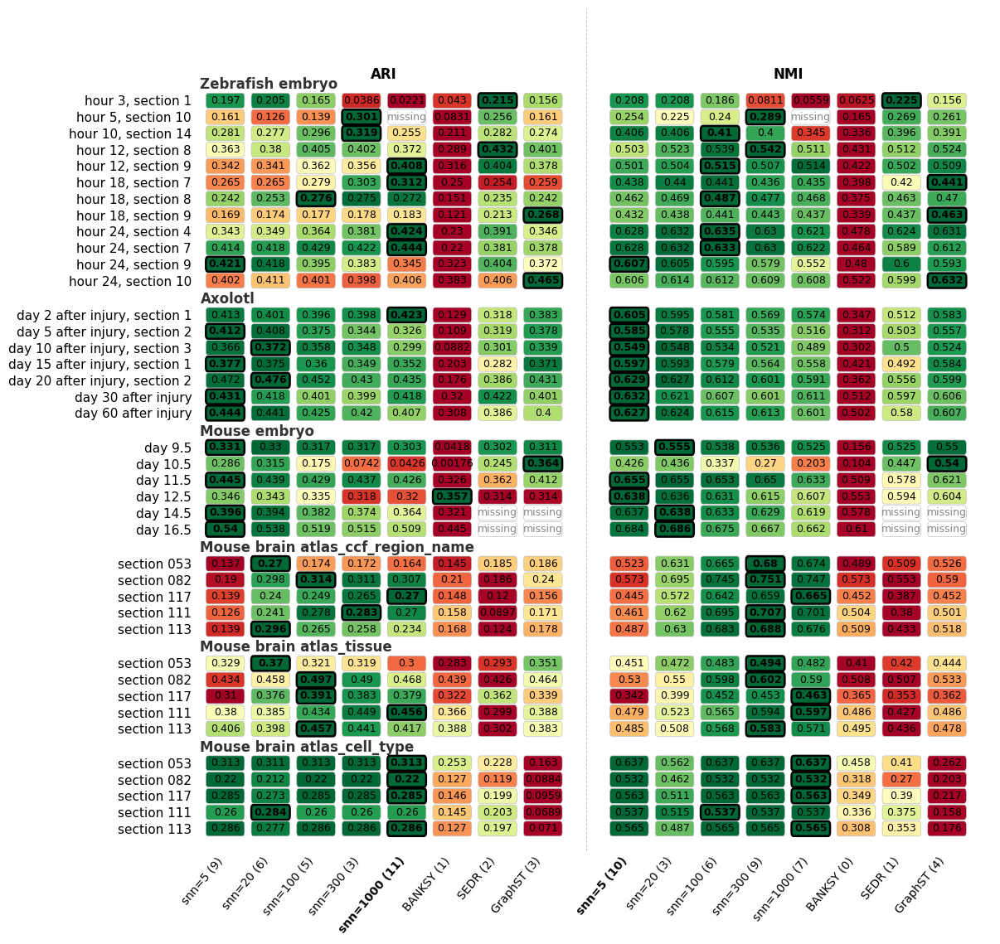

In [35]:
# plt.rcParams['text.usetex'] = True
fig,axes,df2 = plot_sample_heatmap(results_heatmap_supp_snn, metrics = ('ARI','NMI'
                                                                        # ,'HOM','COM'
                                                                        ), agg='mean', rect_width=0.85, rect_height=0.20,fontsize_ticks=10,fontsize_scores=9)
fig.tight_layout()

## Supplementary figures S20

In [36]:
supp_results_se = {}
min_seed,max_seed = 0,100
seeds = range(min_seed,max_seed)
run_all = False # if True, run the benchmark for all the parameters of the loop, otherwise, runs only the parameters for which the result file is missing.  
annotations = ['ccf_region_name','tissue','cell_type']

total_torun = 0
total_done = 0
total_missing = 0
total = 0

methods = {
'Kontext sigma_e=0.2':    {'additional_info':{'name':'sigma_e=0.2'},'matrix':'Kontext',     'embedding':{"sigma_e":0.2, "snn":20, 'alpha':0.5},'spatial_domains':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'image'}},
'Kontext sigma_e=0.4':    {'additional_info':{'name':'sigma_e=0.4'},'matrix':'Kontext',     'embedding':{"sigma_e":0.4, "snn":20, 'alpha':0.5},'spatial_domains':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'image'}},
'Kontext sigma_e=0.6':    {'additional_info':{'name':'sigma_e=0.6'},'matrix':'Kontext',     'embedding':{"sigma_e":0.6, "snn":20, 'alpha':0.5},'spatial_domains':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'image'}},
'Kontext sigma_e=0.8':    {'additional_info':{'name':'sigma_e=0.8'},'matrix':'Kontext',     'embedding':{"sigma_e":0.8, "snn":20, 'alpha':0.5},'spatial_domains':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'image'}},
'Kontext sigma_e=1.0':    {'additional_info':{'name':'sigma_e=1.0'},'matrix':'Kontext',     'embedding':{"sigma_e":1.0, "snn":20, 'alpha':0.5},'spatial_domains':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'image'}},
'Kontext sigma_e=1.2':    {'additional_info':{'name':'sigma_e=1.2'},'matrix':'Kontext',     'embedding':{"sigma_e":1.2, "snn":20, 'alpha':0.5},'spatial_domains':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'image'}},
'Kontext sigma_e=1.4':    {'additional_info':{'name':'sigma_e=1.4'},'matrix':'Kontext',     'embedding':{"sigma_e":1.4, "snn":20, 'alpha':0.5},'spatial_domains':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'image'}},
'Kontext sigma_e=1.6':    {'additional_info':{'name':'sigma_e=1.6'},'matrix':'Kontext',     'embedding':{"sigma_e":1.6, "snn":20, 'alpha':0.5},'spatial_domains':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'image'}},
'Kontext sigma_e=1.8':    {'additional_info':{'name':'sigma_e=1.8'},'matrix':'Kontext',     'embedding':{"sigma_e":1.8, "snn":20, 'alpha':0.5},'spatial_domains':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'image'}},
'Kontext sigma_e=2.0':    {'additional_info':{'name':'sigma_e=2.0'},'matrix':'Kontext',     'embedding':{"sigma_e":2.0, "snn":20, 'alpha':0.5},'spatial_domains':{'clustering':'gmm','seed':0}   ,'preprocessing':{'preprocessing':'image'}},
'BANKSY':{'matrix':'BANKSY','additional_info':{'name':'BANKSY'},'embedding':{'k_geom': 18, 'nbr_weight_decay': 'scaled_gaussian', 'm': 1, 'param_lambda': 0.4, 'n_comps': 50},'spatial_domains':{'clustering':'gmm','seed':0},'preprocessing':{'preprocessing':'BANKSY'}},
'SEDR':{'matrix':'SEDR','additional_info':{'name':'SEDR gmm'},'embedding':{'seed':0},'spatial_domains':{'clustering':'gmm','seed':0},'preprocessing':{'preprocessing':'SEDR'}},
'GraphST':{'matrix':'GraphST','additional_info':{'name':'GraphST gmm'},'embedding':{'seed':0},'spatial_domains':{'clustering':'gmm','seed':0},'preprocessing':{'preprocessing':None}},
}



for dataset,sample in BENCHMARK[:]:
    i = -1
    for annotation in annotations: 
        i+=1
        if dataset == 'MBA':
            data = {'dataset':dataset,'sample':sample,'annotation':annotation}
            results_str = f'{dataset}_{annotation}+{sample}'
            supp_results_se[results_str] = []
        else:
            if i == 0:
                data = {'dataset':dataset,'sample':sample}
                results_str = f'{dataset}+{sample}'
                supp_results_se[results_str] = []

        if dataset == 'MBA' or i == 0:
            for name,param0 in methods.items():  
                if dataset =='MBA':
                    print(results_str,dataset,sample,annotation,name,get_dataset_info()[dataset][sample]['n_obs'])
                else:
                    print(results_str,dataset,sample,name,get_dataset_info()[dataset][sample]['n_obs'])
                matrix = param0['matrix']

                if matrix == 'Kontext':
                    snn1000 =  param0['embedding']['snn']==1000

                matrix = param0['matrix'] 
                executor_params = {
                            'slurm_partition':'common' if matrix in ['Kontext','BANKSY'] else 'ml4ig_gpu',
                            'slurm_cpus_per_task':1,
                            'slurm_array_parallelism':100,
                            'slurm_mem':'100G' if snn1000 else ('100G' if dataset=='MOSTA' else '5G') if matrix in ['Kontext','BANKSY'] else ('200G' if dataset=='MOSTA' else '15G'),#get_needed_mem(dataset,sample,step='all'),
                            'timeout_min':600,
                            'slurm_job_name':f'{name}_{sample}_{annotation}' if dataset == 'MBA' else f'{name}_{sample}',
                            'slurm_srun_args':["--cpu-bind=none"],
                            'slurm_gres': None if matrix in ['Kontext','BANKSY'] else 'gpu:1',
                            }


                params_all = []
                params_done = []
                params_missing = []

                for seed in seeds:


                    param = {k:v.copy() if isinstance(v,dict) else v for k,v in param0.items()}
                    param['root'] = root
                    if matrix == 'Kontext':
                        if dataset == 'MBA':
                            param['preprocessing']['preprocessing'] = 'xenium'
                        else:
                            param['preprocessing']['preprocessing'] = 'large2svg'  

                    param['data'] = data
                    if 'seed' in param['embedding']:
                        param['embedding']['seed'] = seed
                    if 'seed' in param['spatial_domains']:
                        param['spatial_domains']['seed'] = seed
                    if dataset == 'MBA' and matrix == 'Kontext' and 'alpha' not in name:
                        param['embedding']['alpha'] = {'ccf_region_name':0,'tissue':0.1,'cell_type':1.0}[annotation]

                    signature = "_".join(f"{format_key(k)}{format_value(v)}" for k, v in {'matrix':param['matrix'],**param['preprocessing'],**param['embedding'],**param['spatial_domains']}.items() if v is not None and k!='additional_info')
                    path = benchmark_path(data,root=root)
                    p = path / f'{signature}.json'
                    params_all += [param]
                    
                    if not p.exists():
                        # print(p)
                        params_missing += [param]
                    else:
                        params_done += [param]
                        try:
                            with open(p, "r") as f:
                                out = json.load(f)
                        except:
                            print(p)
                            nerr+=1

                        out['name'] = name
                        supp_results_se[results_str] += [out]





    #### Uncomment to run benchmark locally in the loop

                    # run_benchmark_wrapper(param)
                    # run_example(**param)

    ####        

                if dataset == 'MBA':
                    log_name = f"logs4/benchmark_{dataset}_{sample}_{annotation}/{name}/"
                else:
                    log_name = f"logs4/benchmark_{dataset}_{sample}/{matrix}/"

                executor = submitit.AutoExecutor(folder=log_name)
                executor.update_parameters(**executor_params ) 

                params_torun = params_all if run_all else params_missing
                n_torun = len(params_all) if run_all else len(params_missing)
                n_done = len(params_done)
                n_missing = len(params_missing)
                total_torun += n_torun
                total_done += n_done
                total_missing += n_missing
                if n_missing>0:
                    if dataset == 'MBA':
                        print(f'err{nerr} {dataset} {sample} {annotation} {matrix} to_run={n_torun} done={n_done} missing={n_missing} total_torun={total_torun} total_done={total_done} total_missing={total_missing}')
                    else:
                        print(f'err{nerr} {dataset} {sample} {matrix} to_run={n_torun} done={n_done} missing={n_missing} total_torun={total_torun} total_done={total_done} total_missing={total_missing}')

    #### Uncomment to submit jobs with submitit

                # print(executor_params)
                # if len(params_torun)>0:
                #     jobs = executor.map_array(run_benchmark_wrapper,params_torun)

    #####
    

    print('####',dataset,sample,name,len(supp_results_se[results_str]))





ZESTA+zf3_1 ZESTA zf3_1 Kontext sigma_e=0.2 1167
ZESTA+zf3_1 ZESTA zf3_1 Kontext sigma_e=0.4 1167
ZESTA+zf3_1 ZESTA zf3_1 Kontext sigma_e=0.6 1167
ZESTA+zf3_1 ZESTA zf3_1 Kontext sigma_e=0.8 1167
ZESTA+zf3_1 ZESTA zf3_1 Kontext sigma_e=1.0 1167
ZESTA+zf3_1 ZESTA zf3_1 Kontext sigma_e=1.2 1167
ZESTA+zf3_1 ZESTA zf3_1 Kontext sigma_e=1.4 1167
ZESTA+zf3_1 ZESTA zf3_1 Kontext sigma_e=1.6 1167
ZESTA+zf3_1 ZESTA zf3_1 Kontext sigma_e=1.8 1167
ZESTA+zf3_1 ZESTA zf3_1 Kontext sigma_e=2.0 1167
ZESTA+zf3_1 ZESTA zf3_1 BANKSY 1167
ZESTA+zf3_1 ZESTA zf3_1 SEDR 1167
ZESTA+zf3_1 ZESTA zf3_1 GraphST 1167
#### ZESTA zf3_1 GraphST 1300
ZESTA+zf5_10 ZESTA zf5_10 Kontext sigma_e=0.2 563
ZESTA+zf5_10 ZESTA zf5_10 Kontext sigma_e=0.4 563
ZESTA+zf5_10 ZESTA zf5_10 Kontext sigma_e=0.6 563
ZESTA+zf5_10 ZESTA zf5_10 Kontext sigma_e=0.8 563
ZESTA+zf5_10 ZESTA zf5_10 Kontext sigma_e=1.0 563
ZESTA+zf5_10 ZESTA zf5_10 Kontext sigma_e=1.2 563
ZESTA+zf5_10 ZESTA zf5_10 Kontext sigma_e=1.4 563
ZESTA+zf5_10 ZESTA zf5_

In [37]:

results_heatmap_supp_se = {}


for dataset,sample in BENCHMARK:
    for annotation in annotations:
        if dataset == 'MBA':
            ds = f'{dataset}_{annotation}+{sample}'
        else:
            ds = f'{dataset}+{sample}'
        if ds not in supp_results_se:
            continue

        res = supp_results_se[ds]
        new_res_supp_se = []

        for run in res:
            i = run.copy()
            if i['matrix']!= 'Kontext':
                i['name'] = i['matrix']
                new_res_supp_snn += [i]
            else:
                i['name'] = f"sigma_e = {i['sigma_e']}"

            new_res_supp_se +=[i]


        results_heatmap_supp_se[ds] = new_res_supp_se



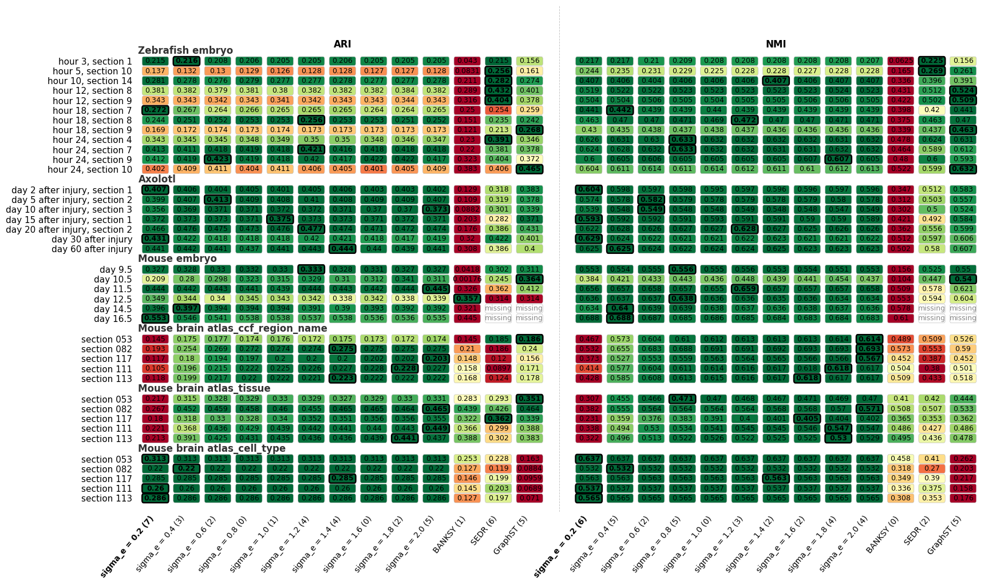

In [38]:

fig,axes,df2 = plot_sample_heatmap(results_heatmap_supp_se, metrics = ('ARI','NMI'
                                                                        #   ,'HOM','COM'
                                                                          ), agg='mean', rect_width=0.85, rect_height=0.20,fontsize_ticks=10,fontsize_scores=9)

## Supplementary figure 21

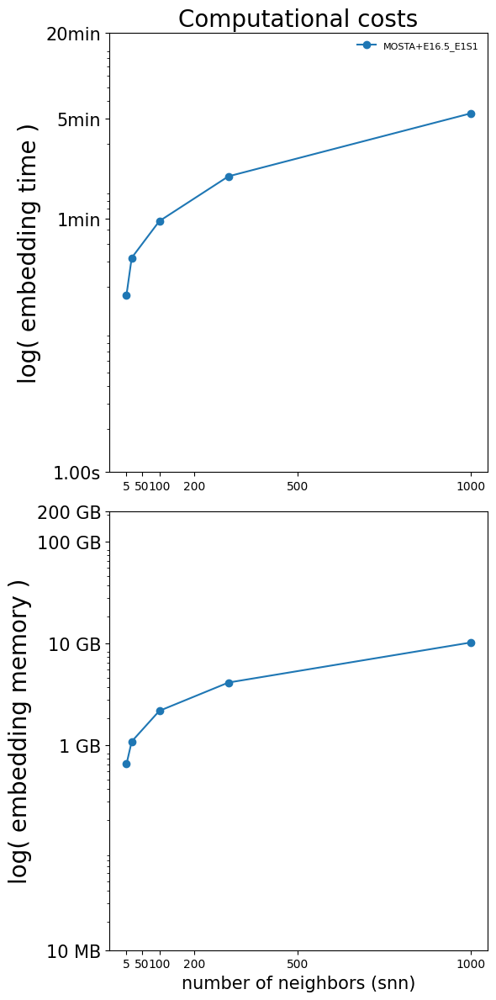

In [39]:
from utils.visualization import FuncFormatter
metrics = ['embedding_time', 'embedding_memory_b']

df = pd.concat([pd.DataFrame(r).assign(key=k) for k, r in results_heatmap_supp_snn_time.items() if r])

fig, axes = get_figs(len(metrics), vert=True)
for ax, met in zip(axes, metrics):
    for key, sub in df.groupby('key'):
        s = sub.groupby('snn')[met].mean().sort_index()
        ax.plot(s.index, s.values, marker='o', label=key)
    # ax.set_xscale('log') 
    ax.set_yscale('log')
    
    snn = [5,50,100,200,500,1000]
    ax.set_xticks(snn)
    ax.set_xticklabels(snn)
    ax.yaxis.set_major_formatter(FuncFormatter(
        lambda v, _: format_time(v) if 'time' in met else format_size(v)))

axes[0].set_title('Computational costs',fontsize=20)
axes[1].set_title('',fontsize=20)
axes[0].set_ylabel('log( embedding time )',fontsize=20)
axes[1].set_ylabel('log( embedding memory )',fontsize=20)


axes[0].set_xlabel('')
axes[1].set_xlabel('number of neighbors (snn)', fontsize=15)
axes[0].legend(fontsize=8, frameon=False)

times = [1,60,60*5,20*60]
memory_sizes = [10*1024*1024,1024*1024*1024,1024**3*10,1024**3*100,1024**3*100*2]
axes[0].set_yticks(times)
axes[0].set_yticklabels([format_time(time).split('-')[0] for time in times],fontsize=15)
axes[1].set_yticks(memory_sizes)
axes[1].set_yticklabels([format_size(memory).replace('.00','') for memory in memory_sizes],fontsize=15)


fig.tight_layout()